# 📚 Прототип книжного рекомендательного сервиса (Goodbooks-10k)

**Цель работы** — реализовать, проанализировать и сравнить разные подходы к рекомендациям на одних и тех же данных:
неперсонализированные (Popularity), контентные (TF-IDF), коллаборативную фильтрацию (Item-based CF) и матричные разложения (SVD),
а затем объединить их в гибридную стратегию, устойчивую к холодному старту.

## Содержание
| Этап | Что делаем |
|---|---|
| **0** | Настройка окружения, константы, воспроизводимость |
| **1** | Загрузка данных и разведочный анализ (EDA), проблемы данных |
| **—** | Подготовка к моделированию: train/test-сплит, разреженные матрицы, метрики Precision@K / Recall@K / nDCG@K |
| **2** | Бейзлайны: Popularity и контентная модель (TF-IDF, `get_similar_books`) |
| **3** | Item-based CF (косинус / adjusted cosine), предсказание оценки, **вычислительная сложность** |
| **4** | Матричное разложение SVD (`surprise`), RMSE, `get_recommendations` |
| **5** | Сравнение всех моделей на отложенной выборке (Top-N метрики) |
| **6** | Гибридная модель против холодного старта + итоговые выводы |

## Ключевые проектные решения (кратко)
* **Ключи таблиц.** В этой версии датасета `books.csv` содержит `id` (1…10000 — именно он используется в `ratings.csv`) и `book_id` (Goodreads-ID — он используется в `book_tags.csv`). Колонки переименованы и связь проверена численно (см. 1.1).
* **Дубликаты.** В `ratings.csv` есть повторные оценки одной пары (user, book) — они удалены.
* **Сплит.** В `ratings.csv` **нет временной метки**, поэтому временной сплит невозможен. Используется случайный **per-user hold-out 80/20** (у каждого пользователя 20 % оценок уходит в test, минимум одна; хотя бы одна остаётся в train) с фиксированным `seed`. Для подбора гиперпараметров train дополнительно делится так же на `train_inner / val` — test в подборе не участвует.
* **Релевантность.** Релевантной считается книга с оценкой **≥ 4** в отложенной части; кандидаты для рекомендации — все книги, которых нет в train-истории пользователя.
* **Метрики.** Precision@K, Recall@K, nDCG@K (бинарные gain, логарифмический дисконт) реализованы векторно и проверены юнит-тестом на ручном примере.
* **Эффективность.** Матрица «пользователь × книга» хранится в `scipy.sparse.csr_matrix`; сходства считаются блоками, рекомендации и метрики — матричными операциями по чанкам пользователей.

> ⏱ Полный прогон ноутбука ≈ 8–10 минут на обычном ноутбуке (память — порядка нескольких ГБ). Все случайные процессы зафиксированы (`SEED = 42`), повторные прогоны дают одинаковые числа.

## Результаты в двух словах (подробности — в разделе 7)
* **Лучшая модель для Top-N — Item-based CF:** nDCG@10 ≈ 0.217, Recall@10 ≈ 0.272; **гибрид** (Item-CF + Content + SVD) даёт значимый прирост до nDCG@10 ≈ 0.222 и умеет рекомендовать новые книги.
* **SVD из `surprise` хорош по RMSE (0.830), но как ранжировщик Top-N бесполезен** (nDCG@10 ≈ 0.001): он обучен предсказывать оценки уже прочитанных книг. Лучший RMSE (0.799) — у Item-CF с поправкой на смещения.
* **Popularity ≈ Random:** в `ratings.csv` на каждую книгу приходится ≈ 100 оценок, поэтому популярность внутри выборки «сплющена».
* **Холодный старт:** для новых книг помогает контентная модель (Recall@10 ≈ 0.31 против ≈ 0.01 у CF-моделей); для новых пользователей достаточно 1–2 оценок.

## Этап 0. Окружение и конфигурация

In [1]:
import re
import time
import warnings
from contextlib import contextmanager
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.utils.extmath import randomized_svd
from surprise import SVD, Dataset, Reader, accuracy

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42                      # единый seed для сплитов, SVD, семплирования
RELEVANCE_THRESHOLD = 4        # оценка >= 4 => книга релевантна / «понравилась»
TEST_FRAC = 0.2                # доля оценок каждого пользователя, уходящая в hold-out
KS = (5, 10, 20)               # значения K для Top-K метрик
MAIN_K = 10                    # «главное» K для сравнения моделей
MIN_RATINGS = 50               # порог числа оценок для Popularity (обоснование — в разделе 2.1)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.labelsize": 11,
                     "legend.fontsize": 9, "axes.titleweight": "bold"})
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)

MODEL_COLORS = {
    "Random": "#b0b0b0", "Popularity (mean rating)": "#8c8c8c", "Popularity (most rated)": "#6e6e6e",
    "Popularity (Goodreads count)": "#a0a0a0",
    "Content-based (TF-IDF)": "#2a9d8f", "Item-based CF": "#e76f51", "SVD (surprise)": "#457b9d",
    "PureSVD (implicit)": "#8d6bb8", "Hybrid": "#e9a319",
}


@contextmanager
def timer(label):
    t0 = time.perf_counter()
    yield
    print(f"⏱ {label}: {time.perf_counter() - t0:.1f} c")


def find_data_dir():
    for cand in (Path("data"), Path("."), Path("../data"), Path("goodbooks-10k")):
        if (cand / "ratings.csv").exists() and (cand / "books.csv").exists():
            return cand
    raise FileNotFoundError("Не найдены CSV датасета Goodbooks-10k. Распакуйте архив в папку ./data "
                            "(books.csv, ratings.csv, tags.csv, book_tags.csv).")


DATA_DIR = find_data_dir()
print("Данные:", DATA_DIR.resolve())

Данные: D:\IdeaProjects\recommenddationFirst\data


# Этап 1. Знакомство с данными и EDA
## 1.1 Загрузка данных

In [2]:
books = pd.read_csv(DATA_DIR / "books.csv")
ratings_raw = pd.read_csv(DATA_DIR / "ratings.csv")
tags = pd.read_csv(DATA_DIR / "tags.csv")
book_tags = pd.read_csv(DATA_DIR / "book_tags.csv")

overview = pd.DataFrame({
    "файл": ["books.csv", "ratings.csv", "tags.csv", "book_tags.csv"],
    "строк": [len(books), len(ratings_raw), len(tags), len(book_tags)],
    "столбцов": [books.shape[1], ratings_raw.shape[1], tags.shape[1], book_tags.shape[1]],
    "содержание": ["метаданные книг (название, авторы, год, средний рейтинг, счётчики)",
                   "оценки пользователей 1–5 (user_id, book_id, rating)",
                   "словарь тегов (tag_id → tag_name)",
                   "теги книг: сколько раз тег назначен книге (goodreads_book_id, tag_id, count)"],
}).set_index("файл")
display(overview)
display(books.head(3).T.iloc[:, :2])

,строк,столбцов,содержание
файл,,,
books.csv,10000,23,"метаданные книг (название, авторы, год, средний рейтинг, счётчики)"
ratings.csv,981756,3,"оценки пользователей 1–5 (user_id, book_id, rating)"
tags.csv,34252,2,словарь тегов (tag_id → tag_name)
book_tags.csv,999912,3,"теги книг: сколько раз тег назначен книге (goodreads_book_id, tag_..."


,0,1
id,1,2
book_id,2767052,3
best_book_id,2767052,3
work_id,2792775,4640799
books_count,272,491
isbn,439023483,439554934
isbn13,9780439023480.0,9780439554930.0
authors,Suzanne Collins,"J.K. Rowling, Mary GrandPré"
original_publication_year,2008.0,1997.0
original_title,The Hunger Games,Harry Potter and the Philosopher's Stone


**Важная деталь схемы данных.** В `books.csv` два «похожих» идентификатора: `id` (1…10000) и `book_id` (Goodreads-ID вроде `2767052`).
`ratings.csv` использует один из них, `book_tags.csv` — другой. Не будем угадывать, а проверим: для правильного ключа
средняя оценка книги, посчитанная по `ratings.csv`, должна коррелировать с `average_rating` из `books.csv`.

In [3]:
mean_by_book = ratings_raw.groupby("book_id")["rating"].mean().rename("mean_in_ratings")
check = []
for key in ("id", "book_id"):
    joined = books.set_index(key)["average_rating"].to_frame().join(mean_by_book, how="inner")
    check.append({"ключ books.csv ↔ ratings.book_id": key, "совпавших книг": len(joined),
                  "corr(средняя оценка)": joined.corr().iloc[0, 1]})
display(pd.DataFrame(check).set_index("ключ books.csv ↔ ratings.book_id").round(3))
assert check[0]["corr(средняя оценка)"] > 0.8 > check[1]["corr(средняя оценка)"], "неверная гипотеза о ключах"

# ratings.book_id ↔ books.id ; book_tags.goodreads_book_id ↔ books.book_id
books = (books.rename(columns={"book_id": "goodreads_book_id", "id": "book_id"})
              .sort_values("book_id").reset_index(drop=True))
print("book_tags.goodreads_book_id покрыт books.goodreads_book_id:",
      f"{book_tags.goodreads_book_id.isin(books.goodreads_book_id).mean():.0%}")

,совпавших книг,corr(средняя оценка)
ключ books.csv ↔ ratings.book_id,,
id,10000,0.879
book_id,812,-0.045


book_tags.goodreads_book_id покрыт books.goodreads_book_id: 100%


Гипотеза подтверждена: `ratings.book_id` ↔ `books.id` (корреляция ≈ 0.88 против ≈ 0 для второго ключа).
Далее в ноутбуке: **`book_id`** — ключ из `ratings.csv` (1…10000), **`goodreads_book_id`** — ключ для `book_tags.csv`.

## 1.2 Качество данных, очистка и индексация

In [4]:
n_dup_rows = ratings_raw.duplicated(["user_id", "book_id"]).sum()
dup_groups = ratings_raw[ratings_raw.duplicated(["user_id", "book_id"], keep=False)].groupby(["user_id", "book_id"])["rating"]
print(f"Повторных оценок одной пары (user, book): {n_dup_rows} строк в {dup_groups.ngroups} парах; "
      f"из них с противоречивыми значениями: {(dup_groups.nunique() > 1).sum()}")
print("Пропуски в ratings.csv:", int(ratings_raw.isna().sum().sum()), "| столбцы:", list(ratings_raw.columns), "(временной метки нет)")

missing = books.isna().sum()
display(missing[missing > 0].rename("пропусков в books.csv").to_frame().assign(доля=lambda d: (d["пропусков в books.csv"] / len(books)).round(3)))

# Для повторов оставляем последнюю оценку (более «свежая» по порядку записи)
ratings = ratings_raw.drop_duplicates(["user_id", "book_id"], keep="last").reset_index(drop=True)

# Компактные индексы строк/столбцов для разреженных матриц
user_ids = np.sort(ratings["user_id"].unique())
book_ids = books["book_id"].to_numpy()
assert (np.diff(book_ids) > 0).all() and set(ratings["book_id"]) <= set(book_ids)
n_users, n_items = len(user_ids), len(book_ids)
ratings["u"] = np.searchsorted(user_ids, ratings["user_id"])
ratings["i"] = np.searchsorted(book_ids, ratings["book_id"])
print(f"После очистки: {len(ratings):,} оценок | {n_users:,} пользователей | {n_items:,} книг")

Повторных оценок одной пары (user, book): 2278 строк в 2209 парах; из них с противоречивыми значениями: 633
Пропуски в ratings.csv: 0 | столбцы: ['book_id', 'user_id', 'rating'] (временной метки нет)


,пропусков в books.csv,доля
isbn,700,0.070
isbn13,585,0.058
original_publication_year,21,0.002
original_title,585,0.058
language_code,1084,0.108


После очистки: 979,478 оценок | 53,424 пользователей | 10,000 книг


* В `original_title` 585 пропусков (≈ 6 %) → при построении контентного профиля подставим `title` без «серии» в скобках.
* Повторные оценки — артефакт сбора данных; оставляем одну оценку на пару, иначе при сплите одна и та же пара могла бы оказаться и в train, и в test (утечка).

## 1.3 Распределение оценок

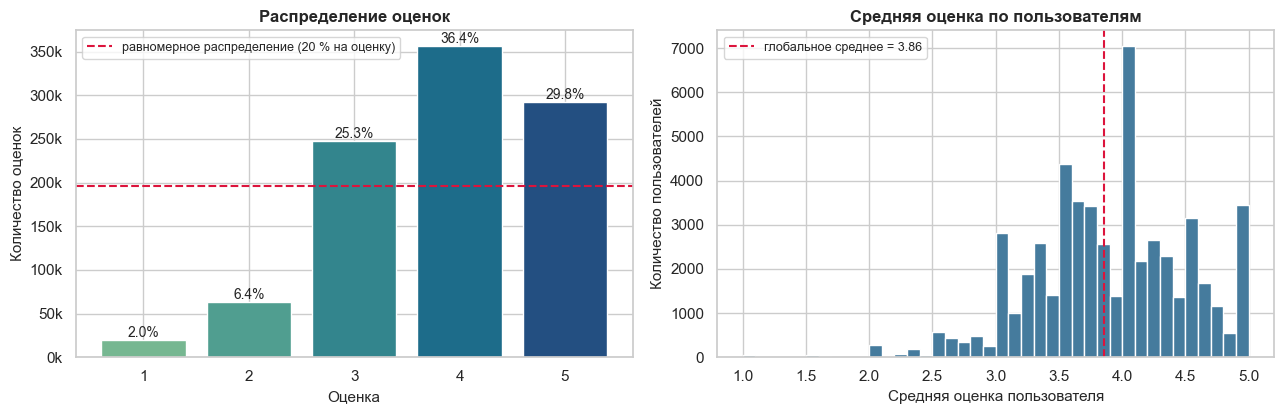

Среднее = 3.856, медиана = 4, std = 0.984
Доля оценок ≥ 4: 66.2% | ≥ 5: 29.8% | ≤ 2: 8.4%


In [5]:
rating_counts = ratings["rating"].value_counts().sort_index()
user_mean_rating = ratings.groupby("user_id")["rating"].mean()
global_mean = ratings["rating"].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
bars = ax.bar(rating_counts.index, rating_counts.values, color=sns.color_palette("crest", 5), edgecolor="white")
for x, c in rating_counts.items():
    ax.text(x, c, f"{c / len(ratings):.1%}", ha="center", va="bottom", fontsize=10)
ax.axhline(len(ratings) / 5, color="crimson", ls="--", label="равномерное распределение (20 % на оценку)")
ax.set(xlabel="Оценка", ylabel="Количество оценок", title="Распределение оценок")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v / 1e3:.0f}k"))
ax.legend(loc="upper left")

ax = axes[1]
ax.hist(user_mean_rating, bins=40, color="#457b9d", edgecolor="white")
ax.axvline(global_mean, color="crimson", ls="--", label=f"глобальное среднее = {global_mean:.2f}")
ax.set(xlabel="Средняя оценка пользователя", ylabel="Количество пользователей", title="Средняя оценка по пользователям")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

print(f"Среднее = {global_mean:.3f}, медиана = {ratings['rating'].median():.0f}, std = {ratings['rating'].std():.3f}")
print(f"Доля оценок ≥ 4: {(ratings.rating >= 4).mean():.1%} | ≥ 5: {(ratings.rating == 5).mean():.1%} | ≤ 2: {(ratings.rating <= 2).mean():.1%}")

**Вывод.** Распределение сильно смещено вправо: оценки 4 и 5 составляют ≈ 66 % всех оценок, оценки 1–2 — лишь ≈ 8 %, мода — 4, среднее ≈ 3.86.
Причина — самоотбор: люди читают и оценивают книги, которые им, скорее всего, понравятся. Следствия:
1. «Глобальное среднее» уже очень сильный предсказатель оценки (RMSE ≈ 0.98), а разнообразие оценок определяется в основном *смещениями* пользователей и книг (щедрые/строгие пользователи, любимые/нелюбимые книги);
2. порог релевантности **≥ 4** даёт ≈ 66 % «положительных» взаимодействий, порог 5 был бы слишком жёстким (≈ 30 %) и слишком шумным (оценка 4 vs 5 — часто вопрос настроения), поэтому берём ≥ 4, как предлагает задание;
3. средние оценки книг отличаются мало (см. `average_rating`: от 2.5 до 4.8 при медиане 4.0), поэтому ранжирование «по среднему рейтингу» чувствительно к шуму — нужен порог на число оценок.

## 1.4 Активность пользователей и холодный старт (пользователи)

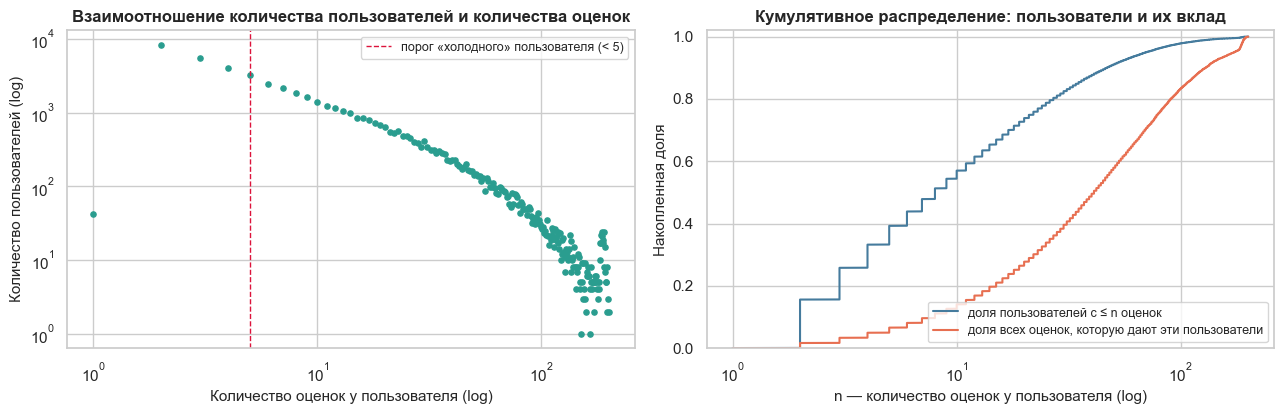

,пользователей,оценок,% пользователей,% оценок
холодные (< 5 оценок),17765,48873,33.3,5.0
редкие (5–19),21047,210393,39.4,21.5
средние (20–49),9704,300912,18.2,30.7
активные (≥ 50),4908,419300,9.2,42.8


{'count': 53424.0, 'mean': 18.3, 'std': 26.2, 'min': 1.0, '25%': 3.0, '50%': 8.0, '75%': 22.0, 'max': 200.0}


In [6]:
user_counts = ratings.groupby("user_id").size()
count_hist = user_counts.value_counts().sort_index()          # n_ratings -> сколько пользователей
ecdf_users = user_counts.sort_values().reset_index(drop=True)
cum_users = (np.arange(1, len(ecdf_users) + 1)) / len(ecdf_users)
cum_ratings = ecdf_users.cumsum() / ecdf_users.sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
ax.scatter(count_hist.index, count_hist.values, s=14, color="#2a9d8f")
ax.set(xscale="log", yscale="log", xlabel="Количество оценок у пользователя (log)", ylabel="Количество пользователей (log)",
       title="Взаимоотношение количества пользователей и количества оценок")
ax.axvline(5, color="crimson", ls="--", lw=1, label="порог «холодного» пользователя (< 5)")
ax.legend()

ax = axes[1]
ax.plot(ecdf_users.values, cum_users, label="доля пользователей с ≤ n оценок", color="#457b9d")
ax.plot(ecdf_users.values, cum_ratings.values, label="доля всех оценок, которую дают эти пользователи", color="#e76f51")
ax.set(xscale="log", xlabel="n — количество оценок у пользователя (log)", ylabel="Накопленная доля",
       title="Кумулятивное распределение: пользователи и их вклад")
ax.legend(loc="lower right"); ax.set_ylim(0, 1.02)
plt.tight_layout(); plt.show()

bins = [0, 4, 19, 49, np.inf]
labels = ["холодные (< 5 оценок)", "редкие (5–19)", "средние (20–49)", "активные (≥ 50)"]
seg = pd.cut(user_counts, bins=bins, labels=labels)
seg_table = user_counts.groupby(seg, observed=True).agg(пользователей="size", оценок="sum")
seg_table["% пользователей"] = (100 * seg_table["пользователей"] / seg_table["пользователей"].sum()).round(1)
seg_table["% оценок"] = (100 * seg_table["оценок"] / seg_table["оценок"].sum()).round(1)
display(seg_table)
print(user_counts.describe().round(1).to_dict())

**Вывод.** Распределение активности — типичный «тяжёлый хвост»: медиана всего **8** оценок, а максимум — ровно 200 (по-видимому, при сборке датасета число оценок на пользователя ограничили сверху).
Около трети пользователей (33 %) имеют < 5 оценок, а более половины (54 %) — < 10, но все «холодные» вместе дают лишь ≈ 5 % взаимодействий; при этом небольшая группа «активных»
(≥ 50 оценок, 9 % пользователей) поставляет ≈ 43 % всех оценок. Для пользователей с 1–4 оценками это **проблема холодного старта**: у них слишком мало истории,
чтобы оценить вкус по коллаборативным сигналам. Ниже (этап 6) мы отдельно измерим качество моделей по сегментам пользователей.

## 1.5 Популярность книг и «длинный хвост»

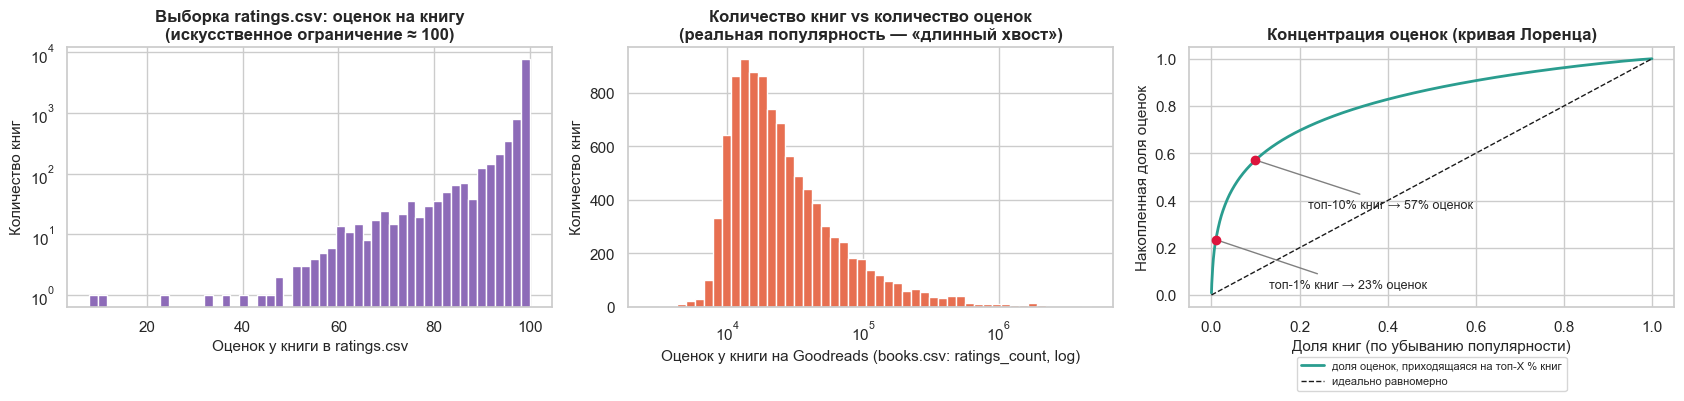

Доля всех оценок Goodreads у топ-1% / 5% / 10% / 20% книг: {'1%': '23%', '5%': '46%', '10%': '57%', '20%': '70%'}
657 книг (6.6% каталога) дают 50 % всех оценок; нижние 50 % книг — 12.8% оценок


,title,authors,average_rating,ratings_count
0,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,4.34,4780653
1,"Harry Potter and the Sorcerer's Stone (Harry Potter, #1)","J.K. Rowling, Mary GrandPré",4.44,4602479
2,"Twilight (Twilight, #1)",Stephenie Meyer,3.57,3866839
3,To Kill a Mockingbird,Harper Lee,4.25,3198671
4,The Great Gatsby,F. Scott Fitzgerald,3.89,2683664


In [7]:
book_counts_sample = ratings.groupby("book_id").size()
rc = books["ratings_count"].sort_values(ascending=False).to_numpy()
cum_share = np.cumsum(rc) / rc.sum()
share_top = {p: cum_share[int(len(rc) * p) - 1] for p in (0.01, 0.05, 0.1, 0.2)}
books_for_half = int(np.searchsorted(cum_share, 0.5) + 1)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
ax = axes[0]
ax.hist(book_counts_sample, bins=50, color="#8d6bb8", edgecolor="white")
ax.set(xlabel="Оценок у книги в ratings.csv", ylabel="Количество книг", yscale="log",
       title="Выборка ratings.csv: оценок на книгу\n(искусственное ограничение ≈ 100)")

ax = axes[1]
ax.hist(books["ratings_count"], bins=np.logspace(np.log10(rc.min()), np.log10(rc.max()), 50), color="#e76f51", edgecolor="white")
ax.set(xscale="log", xlabel="Оценок у книги на Goodreads (books.csv: ratings_count, log)", ylabel="Количество книг",
       title="Количество книг vs количество оценок\n(реальная популярность — «длинный хвост»)")

ax = axes[2]
rank_share = np.arange(1, len(rc) + 1) / len(rc)
ax.plot(rank_share, cum_share, color="#2a9d8f", lw=2, label="доля оценок, приходящаяся на топ-X % книг")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="идеально равномерно")
for p in (0.01, 0.1):
    ax.scatter([p], [share_top[p]], color="crimson", zorder=5)
    ax.annotate(f"топ-{p:.0%} книг → {share_top[p]:.0%} оценок", (p, share_top[p]), xytext=(p + 0.12, share_top[p] - 0.2), fontsize=9,
                arrowprops=dict(arrowstyle="-", color="gray"))
ax.set(xlabel="Доля книг (по убыванию популярности)", ylabel="Накопленная доля оценок", title="Концентрация оценок (кривая Лоренца)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=1, fontsize=8)
plt.tight_layout(); plt.show()

print("Доля всех оценок Goodreads у топ-1% / 5% / 10% / 20% книг:", {f"{p:.0%}": f"{v:.0%}" for p, v in share_top.items()})
print(f"{books_for_half} книг ({books_for_half / len(rc):.1%} каталога) дают 50 % всех оценок; нижние 50 % книг — {1 - cum_share[len(rc) // 2 - 1]:.1%} оценок")
display(books.nlargest(5, "ratings_count")[["title", "authors", "average_rating", "ratings_count"]].reset_index(drop=True))

**Вывод.**
* **Реальная** популярность (поле `ratings_count` из `books.csv`) — классический «длинный хвост»: топ-1 % книг собирает ≈ 23 % всех оценок, топ-10 % — ≈ 57 %, 657 книг (6.6 % каталога) дают половину всех оценок, а нижняя половина каталога — лишь ≈ 13 %.
  Это и есть **смещение популярности** (popularity bias): модели, обученные на «сырых» взаимодействиях, склонны рекомендовать хиты.
* Важная **особенность именно выборки `ratings.csv`**: на каждую книгу приходится ≈ 100 оценок (медиана 100, максимум 100), т.е. создатели датасета ограничили число оценок на книгу.
  Поэтому *внутри нашей выборки* число оценок почти не отражает популярность — хиты «подрезаны», а редкие книги представлены полнее, чем в реальности.
  Это объясняет результаты ниже: «самое популярное» в этой выборке не работает как сильный бейзлайн (чего обычно ожидают от Popularity).

## 1.6 Самые частые теги

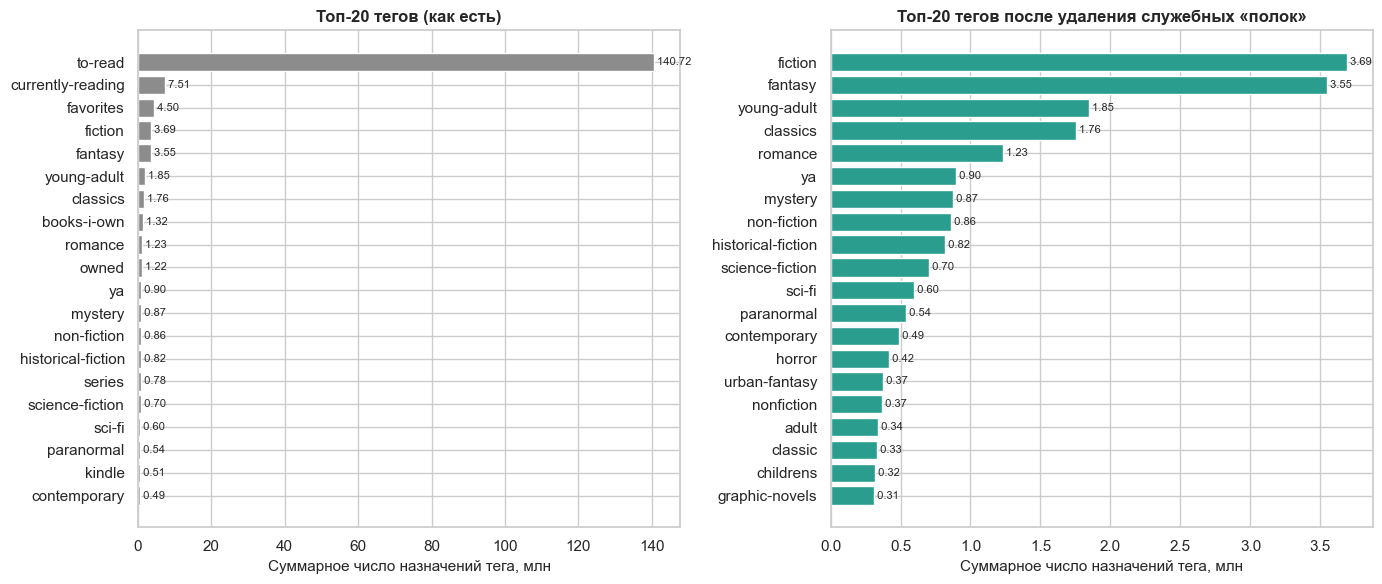

Тегов в словаре: 34,252; из них отнесено к служебным (регулярка): 395 (доля назначений: 79%)
Тегов на книгу в book_tags.csv (медиана): 100


In [8]:
# Служебные «полки» (to-read, favorites, owned…) не описывают содержание книги — исключаем их при построении контентного профиля
SHELF_TAG_RE = (r"^(?:to-?read(?:-.*)?|currently-reading|favou?rites?|favou?rite-books?|all-time-favou?rites?|favs?|my-favou?rites?|"
                r"books-i-own|owned(?:-books?)?|own-it|i-own|own|have|my-books|my-library|library(?:-books?)?|default|kindle|"
                r"e-?books?|audio-?books?|audio|audible|to-buy|wish-?list|read-in-\d{4}|read-\d{4}|re-?read|to-reread|"
                r"dnf|did-not-finish|abandoned|\d-stars?|books|english|school|series|book-club|1001-books|read|reviewed|"
                r"borrowed|tbr|paperback|hardcover|finished|already-read|bookshelf)$")

tag_totals = (book_tags.groupby("tag_id")["count"].sum().rename("total").reset_index().merge(tags, on="tag_id"))
tag_totals["is_shelf"] = tag_totals["tag_name"].str.match(SHELF_TAG_RE)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (title, df_t, color) in zip(axes, [
        ("Топ-20 тегов (как есть)", tag_totals.nlargest(20, "total"), "#8c8c8c"),
        ("Топ-20 тегов после удаления служебных «полок»", tag_totals[~tag_totals.is_shelf].nlargest(20, "total"), "#2a9d8f")]):
    d = df_t.sort_values("total")
    ax.barh(d["tag_name"], d["total"] / 1e6, color=color)
    ax.set(xlabel="Суммарное число назначений тега, млн", title=title)
    for y, v in enumerate(d["total"] / 1e6):
        ax.text(v, y, f" {v:.2f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()
print(f"Тегов в словаре: {len(tags):,}; из них отнесено к служебным (регулярка): {tag_totals.is_shelf.sum()} "
      f"(доля назначений: {tag_totals.loc[tag_totals.is_shelf, 'total'].sum() / tag_totals['total'].sum():.0%})")
print("Тегов на книгу в book_tags.csv (медиана):", int(book_tags.groupby("goodreads_book_id").size().median()))

**Вывод.** Без очистки доминируют «полки» пользователей (`to-read`, `currently-reading`, `favorites`, `owned`…) — на них приходится подавляющая доля всех назначений тегов, но содержания книги они не описывают.
После фильтрации видны настоящие жанровые теги: `fiction`, `fantasy`, `young-adult`, `classics`, `romance`, `mystery`, `non-fiction`, `historical-fiction`, `science-fiction`… —
именно они пригодны для контентной модели (этап 2.2).

## 1.7 Разреженность матрицы взаимодействий

Матрица 53,424 × 10,000 = 534 млн ячеек; заполнено 979,478 (0.183%); разреженность 99.817%
Память: плотная float32 ≈ 2.1 ГБ  vs  CSR ≈ 8.0 МБ  (экономия в ≈ 265 раз)


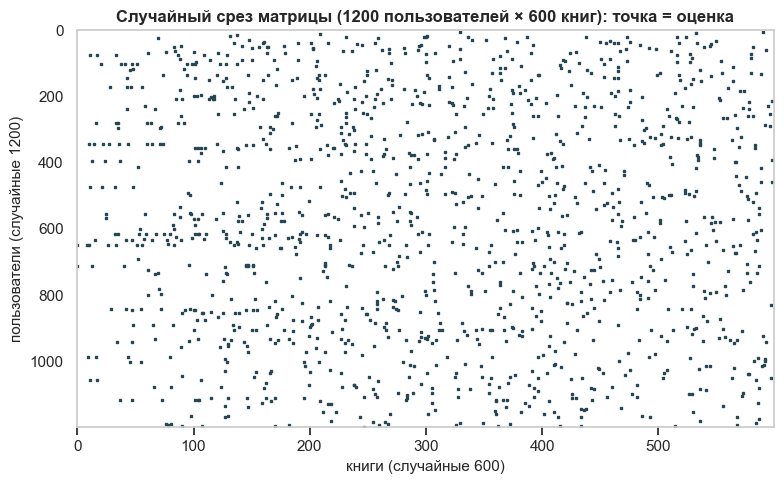

In [9]:
R_full = sp.csr_matrix((np.ones(len(ratings), dtype=np.float32), (ratings.u, ratings.i)), shape=(n_users, n_items))
density = R_full.nnz / (n_users * n_items)
dense_gb = n_users * n_items * 4 / 1e9
sparse_mb = (R_full.data.nbytes + R_full.indices.nbytes + R_full.indptr.nbytes) / 1e6
print(f"Матрица {n_users:,} × {n_items:,} = {n_users * n_items / 1e6:,.0f} млн ячеек; заполнено {R_full.nnz:,} ({density:.3%}); разреженность {1 - density:.3%}")
print(f"Память: плотная float32 ≈ {dense_gb:.1f} ГБ  vs  CSR ≈ {sparse_mb:.1f} МБ  (экономия в ≈ {dense_gb * 1e3 / sparse_mb:.0f} раз)")

rng = np.random.default_rng(SEED)
rows, cols = np.sort(rng.choice(n_users, 1200, replace=False)), np.sort(rng.choice(n_items, 600, replace=False))
fig, ax = plt.subplots(figsize=(8, 5))
ax.spy(R_full[rows][:, cols], markersize=1.5, color="#264653", aspect="auto")
ax.grid(False); ax.xaxis.tick_bottom(); ax.xaxis.set_label_position("bottom")
ax.set(title="Случайный срез матрицы (1200 пользователей × 600 книг): точка = оценка",
       xlabel="книги (случайные 600)", ylabel="пользователи (случайные 1200)")
plt.tight_layout(); plt.show()

## 1.8 Основные проблемы данных (ответ на вопрос задания)

В таблице — количественное резюме того, что видно уже на этапе EDA.

In [10]:
facts = pd.DataFrame([
    ("Разреженность матрицы user×item", f"{1 - density:.2%}", "у среднего пользователя оценено ≈ 0.2 % каталога; общих оценок на пару книг очень мало"),
    ("Пользователи с < 5 оценками (холодный старт)", f"{(user_counts < 5).mean():.0%}", "для них коллаборативные сигналы почти отсутствуют"),
    ("Пользователи с < 10 оценками", f"{(user_counts < 10).mean():.0%}", "«лёгкие» пользователи — основная масса; медиана = %d оценок" % user_counts.median()),
    ("Пользователи с ≥ 50 оценками", f"{(user_counts >= 50).mean():.1%} (дают {user_counts[user_counts >= 50].sum() / user_counts.sum():.0%} оценок)", "малая группа определяет сходства между книгами"),
    ("Доля оценок ≥ 4", f"{(ratings.rating >= 4).mean():.0%}", "положительное смещение шкалы (самоотбор)"),
    ("Топ-1 % книг — доля оценок Goodreads", f"{share_top[0.01]:.0%}", "смещение популярности (popularity bias) в реальных данных"),
    ("Оценок на книгу в ratings.csv (мин / медиана / макс)", f"{book_counts_sample.min()} / {int(book_counts_sample.median())} / {book_counts_sample.max()}", "выборка «подрезана» ≈ 100 оценками на книгу → популярность внутри выборки сглажена"),
    ("Временная метка в ratings.csv", "нет", "временной сплит невозможен → случайный per-user hold-out"),
    ("Дубликаты (user, book)", f"{n_dup_rows}", "удалены"),
    ("Пропуски original_title", f"{books.original_title.isna().sum()} ({books.original_title.isna().mean():.1%})", "для профиля подставляем title без серии"),
    ("Служебные теги-«полки»", f"{tag_totals.loc[tag_totals.is_shelf, 'total'].sum() / tag_totals['total'].sum():.0%} всех назначений", "шум для контентной модели → фильтруем"),
], columns=["показатель", "значение", "комментарий"]).set_index("показатель")
display(facts)

,значение,комментарий
показатель,,
Разреженность матрицы user×item,99.82%,у среднего пользователя оценено ≈ 0.2 % каталога; общих оценок на ...
Пользователи с < 5 оценками (холодный старт),33%,для них коллаборативные сигналы почти отсутствуют
Пользователи с < 10 оценками,54%,«лёгкие» пользователи — основная масса; медиана = 8 оценок
Пользователи с ≥ 50 оценками,9.2% (дают 43% оценок),малая группа определяет сходства между книгами
Доля оценок ≥ 4,66%,положительное смещение шкалы (самоотбор)
Топ-1 % книг — доля оценок Goodreads,23%,смещение популярности (popularity bias) в реальных данных
Оценок на книгу в ratings.csv (мин / медиана / макс),8 / 100 / 100,выборка «подрезана» ≈ 100 оценками на книгу → популярность внутри ...
Временная метка в ratings.csv,нет,временной сплит невозможен → случайный per-user hold-out
"Дубликаты (user, book)",2278,удалены


**Ответ на вопрос «Какие основные проблемы данных видны уже на этапе EDA?»**

1. **Разреженность.** Матрица «пользователь × книга» заполнена на ≈ 0.18 % (разреженность ≈ 99.8 %). Следствия: (а) любые «плотные» операции невозможны по памяти (≈ 2 ГБ против ≈ 8 МБ в CSR) — нужны разреженные структуры;
   (б) две случайные книги почти никогда не имеют большого числа общих оценщиков, поэтому оценки сходства (Item-CF, Pearson/cosine) шумные, особенно для редких пар — полезны *shrinkage* и ограничение `top-K` соседей;
   (в) для классических моделей, обученных только на оценках, не хватает сигнала.
2. **Холодный старт.** Пользовательская активность распределена по тяжёлому хвосту: медиана — 8 оценок, каждый четвёртый пользователь поставил не более 3 оценок, а 33 % — меньше 5. Для таких пользователей персонализация по истории ненадёжна;
   аналогично для новых книг (0 оценок) CF бессилен — нужны контентные признаки (теги, названия). Это мотивирует гибридную модель (этап 6).
3. **Смещение популярности.** В реальных данных Goodreads (`ratings_count`) топ-1 % книг даёт ≈ 23 % всех оценок, а топ-10 % — ≈ 57 %. Модели на «сырых» оценках будут смещаться к хитам (низкое разнообразие, малое покрытие каталога),
   а оценка качества по «угаданным» оценкам будет завышать модели, рекомендующие популярное. Дополнительно *выборка* `ratings.csv` искусственно ограничена ≈ 100 оценками на книгу — это ослабляет популярностное смещение внутри выборки, но делает разреженность по книгам равномерной.
4. **Смещение шкалы оценок** (≈ 66 % оценок ≥ 4): положительный перекос и индивидуальные «смещения» пользователей/книг → оценки нужно центрировать (user/item bias), а порог релевантности выбирать осознанно (≥ 4).
5. **Качество метаданных и тегов:** пропуски `original_title`, множество служебных «полок» среди тегов, дубликаты оценок, отсутствие времени оценки.

# Подготовка к моделированию
## P.1 Разделение данных: train / test (и train_inner / val для подбора гиперпараметров)

Временной сплит невозможен (нет timestamp), поэтому делаем **per-user hold-out**: для каждого пользователя случайно выбираем 20 % его оценок (минимум 1) в test,
остальные — в train. Так каждый пользователь есть и в train (у модели есть «профиль»), и в test (есть что проверять); исключение — несколько десятков пользователей
с единственной оценкой (после удаления дубликатов), они остаются только в train. Всё выполняется векторно через ранги внутри группы.
Для подбора гиперпараметров (и весов гибрида) тот же приём применяется внутри train → `train_inner / val`; **test в подборе не участвует**.

In [11]:
def per_user_split(df, test_frac=TEST_FRAC, seed=SEED):
    """Случайный hold-out внутри каждого пользователя: round-down(test_frac * n_u), но не меньше 1 и не больше n_u - 1."""
    rnd = pd.Series(np.random.default_rng(seed).random(len(df)), index=df.index)
    rank_in_user = rnd.groupby(df["u"]).rank(method="first")
    n_u = df.groupby("u")["i"].transform("size")
    is_test = (rank_in_user <= np.maximum(1, np.floor(test_frac * n_u))) & (n_u >= 2)
    return df[~is_test].copy(), df[is_test].copy()


train, test = per_user_split(ratings)
train_inner, val = per_user_split(train, seed=SEED + 1)

# --- проверки корректности сплита
key = lambda d: d["u"].to_numpy().astype(np.int64) * n_items + d["i"].to_numpy()
assert not np.intersect1d(key(train), key(test)).size, "утечка: пары (user, book) пересекаются"
assert set(test.u) <= set(train.u) and set(val.u) <= set(train_inner.u), "у каждого пользователя в test должна быть история в train"
assert len(train) + len(test) == len(ratings)

split_info = pd.DataFrame({
    "оценок": [len(train), len(test), len(train_inner), len(val)],
    "пользователей": [train.u.nunique(), test.u.nunique(), train_inner.u.nunique(), val.u.nunique()],
    "релевантных (≥ 4)": [(train.rating >= RELEVANCE_THRESHOLD).sum(), (test.rating >= RELEVANCE_THRESHOLD).sum(),
                          (train_inner.rating >= RELEVANCE_THRESHOLD).sum(), (val.rating >= RELEVANCE_THRESHOLD).sum()],
}, index=["train", "test (финальная оценка)", "train_inner", "val (подбор гиперпараметров)"])
display(split_info)

,оценок,пользователей,релевантных (≥ 4)
train,788503,53424,522416
test (финальная оценка),190975,53382,126239
train_inner,639011,53424,423488
val (подбор гиперпараметров),149492,45071,98928


## P.2 Разреженные матрицы взаимодействий

Для каждого сплита строим `SplitData` с тремя CSR-матрицами (float32):
* `R` — явные оценки (для моделей, предсказывающих рейтинг: Item-CF-регрессия, SVD);
* `R_seen` — бинарная «пользователь взаимодействовал с книгой» (любая оценка): ею маскируем уже виденные книги и обучаем неявные модели;
* `R_like` — бинарная «оценка ≥ 4» (явный сигнал «понравилось»);
* `rel` — бинарная матрица **релевантных отложенных** книг (оценка ≥ 4 в test/val) — то, что мы пытаемся угадать.

In [12]:
def build_matrix(df, values=None):
    """CSR-матрица (n_users × n_items); values=None → бинарная."""
    data = np.ones(len(df), dtype=np.float32) if values is None else df[values].to_numpy(dtype=np.float32)
    return sp.csr_matrix((data, (df["u"].to_numpy(), df["i"].to_numpy())), shape=(n_users, n_items))


@dataclass
class SplitData:
    train_df: pd.DataFrame
    test_df: pd.DataFrame

    def __post_init__(self):
        liked = self.train_df[self.train_df.rating >= RELEVANCE_THRESHOLD]
        self.R = build_matrix(self.train_df, "rating")
        self.R_seen = build_matrix(self.train_df)
        self.R_like = build_matrix(liked)
        self.rel = build_matrix(self.test_df[self.test_df.rating >= RELEVANCE_THRESHOLD])
        self.eval_users = users_with_relevant(self.rel)
        self.item_support = np.asarray(self.R_seen.sum(axis=0)).ravel()      # число оценок книги в train
        self.user_support = np.diff(self.R_seen.indptr)                       # число оценок пользователя в train


def users_with_relevant(rel):
    """Пользователи, у которых в отложенной части есть хотя бы одна релевантная книга (только они участвуют в оценке)."""
    return np.flatnonzero(np.diff(rel.indptr) > 0)


outer = SplitData(train, test)               # финальное обучение / оценка
inner = SplitData(train_inner, val)          # подбор гиперпараметров
print(f"outer: R {outer.R.shape}, nnz={outer.R.nnz:,}; пользователей для оценки Top-N: {len(outer.eval_users):,} "
      f"({len(outer.eval_users) / n_users:.0%} — у остальных в test нет оценок ≥ 4)")
print(f"inner: nnz={inner.R.nnz:,}; пользователей для оценки: {len(inner.eval_users):,}")

outer: R (53424, 10000), nnz=788,503; пользователей для оценки Top-N: 42,523 (80% — у остальных в test нет оценок ≥ 4)
inner: nnz=639,011; пользователей для оценки: 35,967


## P.3 Метрики Top-N: Precision@K, Recall@K, nDCG@K

Для пользователя *u* и списка рекомендаций длины *K* (по убыванию score), `rel_k ∈ {0,1}` — релевантна ли книга на позиции *k*, `R_u` — множество релевантных отложенных книг:

$$\mathrm{Precision@K}=\frac{\sum_{k\le K} rel_k}{K},\qquad \mathrm{Recall@K}=\frac{\sum_{k\le K} rel_k}{|R_u|},$$
$$\mathrm{DCG@K}=\sum_{k=1}^{K}\frac{rel_k}{\log_2(k+1)},\qquad \mathrm{nDCG@K}=\frac{\mathrm{DCG@K}}{\mathrm{IDCG@K}},\quad \mathrm{IDCG@K}=\sum_{k=1}^{\min(K,|R_u|)}\frac{1}{\log_2(k+1)}.$$

nDCG учитывает **порядок**: попадание на 1-й позиции весит 1, на 2-й — 0.63, на 10-й — 0.29. Метрики считаются по каждому пользователю и усредняются (macro-average).
Реализация полностью векторная: на вход — матрица индексов рекомендаций `(n_users × K)` и булева матрица релевантности.

In [13]:
def top_k(scores, seen, k):
    """Индексы k книг с наибольшим score для каждой строки; уже виденные книги (seen — CSR) исключаются. Порядок — по убыванию score."""
    scores = np.array(scores, dtype=np.float32)                 # копия: исходный массив (может быть read-only) не портим
    rows = np.repeat(np.arange(seen.shape[0]), np.diff(seen.indptr))
    scores[rows, seen.indices] = -np.inf
    part = np.argpartition(-scores, k, axis=1)[:, :k]           # O(n) отбор k лучших
    order = np.argsort(-np.take_along_axis(scores, part, 1), axis=1)
    return np.take_along_axis(part, order, 1)


def ranking_metrics(top, rel, ks=KS):
    """top: (n, Kmax) рекомендованные книги по убыванию; rel: (n, n_items) bool. Возвращает {'P@k','R@k','nDCG@k'} по пользователям."""
    hits = np.take_along_axis(rel, top, axis=1)                                   # (n, Kmax) bool
    n_rel = rel.sum(axis=1)                                                       # |R_u| >= 1
    discount = 1.0 / np.log2(np.arange(2, top.shape[1] + 2))                      # 1 / log2(rank + 1)
    ideal_cum = np.cumsum(discount)
    out = {}
    for k in ks:
        n_hit = hits[:, :k].sum(axis=1)
        out[f"P@{k}"] = n_hit / k
        out[f"R@{k}"] = n_hit / n_rel
        dcg = (hits[:, :k] * discount[:k]).sum(axis=1)
        out[f"nDCG@{k}"] = dcg / ideal_cum[np.minimum(n_rel, k) - 1]              # IDCG: все релевантные — в начале списка
    return out


# --- юнит-тест на ручном примере: рекомендации [a,b,c,d,e], релевантные {a, c, x}
_top = np.array([[0, 1, 2, 3, 4]]); _rel = np.zeros((1, 10), dtype=bool); _rel[0, [0, 2, 7]] = True
_m = ranking_metrics(_top, _rel, ks=(5,))
_dcg, _idcg = 1 / np.log2(2) + 1 / np.log2(4), 1 / np.log2(2) + 1 / np.log2(3) + 1 / np.log2(4)
assert np.isclose(_m["P@5"][0], 2 / 5) and np.isclose(_m["R@5"][0], 2 / 3) and np.isclose(_m["nDCG@5"][0], _dcg / _idcg)
assert np.isclose(ranking_metrics(np.array([[0, 2, 7, 1, 3]]), _rel, ks=(5,))["nDCG@5"][0], 1.0)             # идеальный порядок → 1
assert ranking_metrics(np.array([[1, 3, 4, 0, 2]]), _rel, ks=(5,))["nDCG@5"][0] < _m["nDCG@5"][0]            # хиты ниже → nDCG меньше
print(f"✓ метрики прошли тест: P@5={_m['P@5'][0]:.3f}, R@5={_m['R@5'][0]:.3f}, nDCG@5={_m['nDCG@5'][0]:.4f} (ожидалось {_dcg / _idcg:.4f})")

✓ метрики прошли тест: P@5=0.400, R@5=0.667, nDCG@5=0.7039 (ожидалось 0.7039)


## P.4 Единый интерфейс моделей и протокол оценки

Каждая модель — наследник `Recommender` с методом `score(users)` (матрица оценок «пользователь × книга» для чанка пользователей) или собственным `recommend`.
Оценка идёт **по чанкам пользователей (2000)**, чтобы не хранить в памяти матрицу 53k × 10k.

**Протокол:** кандидаты — все книги, кроме виденных пользователем в train; релевантные — отложенные книги с оценкой ≥ 4; в оценке участвуют пользователи, у которых есть хотя бы одна релевантная отложенная книга;
метрики — Precision/Recall/nDCG@{5,10,20}, усреднённые по пользователям, с 95 % доверительными интервалами.

In [14]:
class Recommender:
    """Базовый класс: score(users) → (len(users), n_items); recommend() маскирует виденное и берёт top-K."""
    name = "base"

    def score(self, users):
        raise NotImplementedError

    def recommend(self, users, k, seen):
        return top_k(self.score(users), seen, k)


@dataclass
class EvalResult:
    users: np.ndarray
    recs: np.ndarray                    # (n, Kmax) индексы рекомендованных книг
    metrics: dict                       # {'P@10': array по пользователям, ...}

    def mean(self):
        return {k: float(v.mean()) for k, v in self.metrics.items()}


def get_recommendations_batch(model, data, users, k, chunk=2000):
    return np.vstack([model.recommend(users[s:s + chunk], k, data.R_seen[users[s:s + chunk]]) for s in range(0, len(users), chunk)])


def metrics_from_recs(recs, users, rel, ks=KS, chunk=4000):
    parts = [ranking_metrics(recs[s:s + chunk], rel[users[s:s + chunk]].toarray().astype(bool), ks) for s in range(0, len(users), chunk)]
    return {name: np.concatenate([p[name] for p in parts]) for name in parts[0]}


def evaluate(model, data, users=None, ks=KS, rel=None):
    users = data.eval_users if users is None else users
    recs = get_recommendations_batch(model, data, users, max(ks))
    return EvalResult(users, recs, metrics_from_recs(recs, users, data.rel if rel is None else rel, ks))


def ci95(x):
    return 1.96 * x.std(ddof=1) / np.sqrt(len(x))


def summary_table(results, ks=KS):
    """Сводная таблица: строки — модели, столбцы — (метрика, K)."""
    cols = [(m, k) for m in ("P", "R", "nDCG") for k in ks]
    names = {"P": "Precision", "R": "Recall", "nDCG": "nDCG"}
    table = pd.DataFrame({name: {(names[m], f"@{k}"): r.metrics[f"{m}@{k}"].mean() for m, k in cols} for name, r in results.items()}).T
    table.columns = pd.MultiIndex.from_tuples(table.columns)
    return table


def show_table(df, fmt="{:.4f}"):
    display(df.style.format(fmt).highlight_max(axis=0, props="font-weight:bold; background-color:#d8f3dc"))

# Этап 2. Базовые и контентные модели
## 2.1 Неперсонализированная модель: Top-N по среднему рейтингу с порогом числа оценок

Идея: показать всем одни и те же «лучшие» книги. Сортировка по голому среднему рейтингу ненадёжна: у книги с 3 оценками «5.0» шум огромен.
Стандартная ошибка среднего ≈ σ / √n; при σ ≈ 1 и **n = 50** она ≈ 0.14, а при n = 10 — ≈ 0.32. Поэтому вводим порог `MIN_RATINGS = 50`.
В нашей выборке (≈ 80 оценок на книгу в train) он отсекает всего ≈ 100 книг; на реальных данных с длинным хвостом отсечение было бы куда существеннее.
Функция использует **только обучающую часть** (иначе в оценке будет утечка).

,book_id,mean_rating,n_ratings,title,authors
0,6361,4.807,83,There's Treasure Everywhere: A Calvin and Hobbes Collection,Bill Watterson
1,7947,4.794,63,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem"
2,6920,4.793,82,The Indispensable Calvin and Hobbes,Bill Watterson
3,5207,4.790,81,The Days Are Just Packed: A Calvin and Hobbes Collection,Bill Watterson
4,3275,4.776,85,"Harry Potter Boxed Set, Books 1-5 (Harry Potter, #1-5)","J.K. Rowling, Mary GrandPré"
5,8978,4.770,87,The Revenge of the Baby-Sat,Bill Watterson
6,9806,4.765,51,"One Piece, Volume 38: Rocketman!! (One Piece, #38)",Eiichirō Oda
7,9566,4.762,84,Attack of the Deranged Mutant Killer Monster Snow Goons,Bill Watterson
8,8109,4.757,74,"The Absolute Sandman, Volume One","Neil Gaiman, Mike Dringenberg, Chris Bachalo, Michael Zulli, Kelly..."
9,4483,4.750,80,It's a Magical World: A Calvin and Hobbes Collection,Bill Watterson


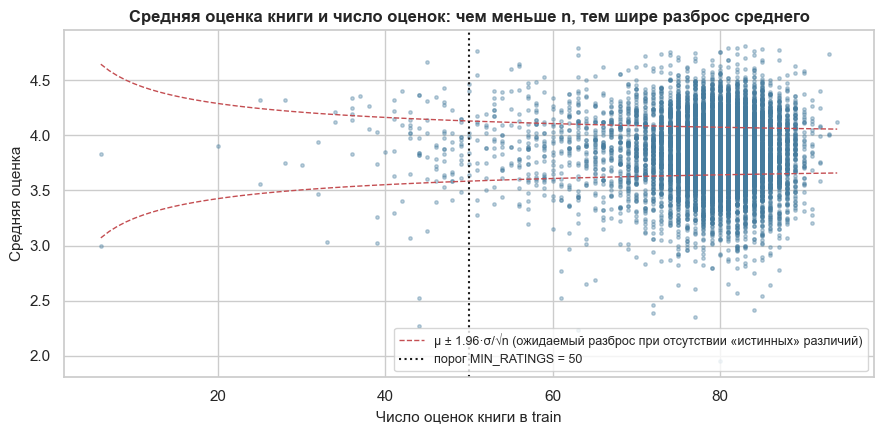

Книг, отсекаемых порогом (< 50 оценок в train): 104 из 10000 (стандартная ошибка среднего: n=8 → 0.35, n=50 → 0.14, n=80 → 0.11)


In [15]:
def popular_books(n=10, min_ratings=MIN_RATINGS, train_df=train):
    """Top-N книг по среднему рейтингу среди книг, у которых не менее min_ratings оценок."""
    stats = train_df.groupby("book_id")["rating"].agg(mean_rating="mean", n_ratings="size")
    stats = stats[stats.n_ratings >= min_ratings].sort_values(["mean_rating", "n_ratings"], ascending=False).head(n)
    return stats.join(books.set_index("book_id")[["title", "authors"]]).reset_index()


display(popular_books(10).round({"mean_rating": 3}))

# Почему нужен порог: воронкообразный график «средняя оценка vs число оценок»
stats_tr = train.groupby("book_id")["rating"].agg(mean_rating="mean", n_ratings="size")
sigma = train["rating"].std()
n_axis = np.arange(stats_tr.n_ratings.min(), stats_tr.n_ratings.max() + 1)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(stats_tr.n_ratings, stats_tr.mean_rating, s=6, alpha=0.35, color="#457b9d")
ax.plot(n_axis, train.rating.mean() + 1.96 * sigma / np.sqrt(n_axis), "r--", lw=1, label="μ ± 1.96·σ/√n (ожидаемый разброс при отсутствии «истинных» различий)")
ax.plot(n_axis, train.rating.mean() - 1.96 * sigma / np.sqrt(n_axis), "r--", lw=1)
ax.axvline(MIN_RATINGS, color="k", ls=":", label=f"порог MIN_RATINGS = {MIN_RATINGS}")
ax.set(xlabel="Число оценок книги в train", ylabel="Средняя оценка", title="Средняя оценка книги и число оценок: чем меньше n, тем шире разброс среднего")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
print(f"Книг, отсекаемых порогом (< {MIN_RATINGS} оценок в train): {(stats_tr.n_ratings < MIN_RATINGS).sum()} из {len(stats_tr)} "
      f"(стандартная ошибка среднего: n=8 → {sigma / np.sqrt(8):.2f}, n={MIN_RATINGS} → {sigma / np.sqrt(MIN_RATINGS):.2f}, n=80 → {sigma / np.sqrt(80):.2f})")

In [16]:
class StaticScoreRecommender(Recommender):
    """Неперсонализированная модель: один и тот же вектор score для всех (виденные книги пользователя исключаются при ранжировании)."""

    def __init__(self, item_scores, name="static"):
        self.s, self.name = np.asarray(item_scores, dtype=np.float32), name

    def score(self, users):
        return np.broadcast_to(self.s, (len(users), len(self.s)))


class RandomRecommender(Recommender):
    name = "Random"

    def __init__(self, seed=SEED):
        self.rng = np.random.default_rng(seed)

    def score(self, users):
        return self.rng.random((len(users), n_items), dtype=np.float32)


def popularity_scores(train_df, strategy="mean", min_ratings=MIN_RATINGS, damping=50):
    """mean — средний рейтинг (книги с < min_ratings оценок исключены); count — число оценок; bayes — рейтинг со сглаживанием к глобальному среднему."""
    g = train_df.groupby("i")["rating"].agg(["mean", "size"]).reindex(range(n_items))
    n, mean = g["size"].fillna(0).to_numpy(), g["mean"].fillna(0).to_numpy()
    if strategy == "mean":
        return np.where(n >= min_ratings, mean, -np.inf)
    if strategy == "count":
        return n
    return (n * mean + damping * train_df.rating.mean()) / (n + damping)


pop_mean = StaticScoreRecommender(popularity_scores(train, "mean"), "Popularity (mean rating)")
pop_count = StaticScoreRecommender(popularity_scores(train, "count"), "Popularity (most rated)")
pop_goodreads = StaticScoreRecommender(books["ratings_count"].to_numpy(), "Popularity (Goodreads count)")     # диагностика: внешняя статистика books.csv
print("Popularity готова: единый список для всех пользователей, индивидуально исключаются уже виденные книги.")

Popularity готова: единый список для всех пользователей, индивидуально исключаются уже виденные книги.


## 2.2 Контентная модель: TF-IDF по названию и тегам

**Профиль книги** = `original_title` (если пропущен — `title` без скобок с серией) + её теги. Что делаем с тегами:
1. убираем служебные «полки» (to-read, favorites, owned…), см. EDA 1.6;
2. берём **топ-20 тегов** по `count` (сколько раз тег назначили книге);
3. каждый тег повторяем от 1 до 5 раз пропорционально его доле от самого частого тега книги (так сильнее выраженные теги получают больший TF-вес);
4. дефисы в тегах заменяем на `_`, чтобы `science-fiction` и `young-adult` остались цельными токенами.

Затем — `TfidfVectorizer` (стоп-слова, сублинейный TF, `min_df=2`, `max_df=0.5`). Строки TF-IDF матрицы L2-нормированы ⇒ косинусная близость = скалярное произведение.

In [17]:
def build_profiles(top_tags=20, max_repeat=5):
    bt = book_tags.merge(tags, on="tag_id")
    bt = bt[~bt.tag_name.str.match(SHELF_TAG_RE)]
    bt = bt.groupby(["goodreads_book_id", "tag_name"], as_index=False)["count"].sum()           # в данных есть 8 дублей (книга, тег)
    bt = bt.sort_values(["goodreads_book_id", "count"], ascending=[True, False])
    bt = bt[bt.groupby("goodreads_book_id").cumcount() < top_tags].copy()
    reps = np.ceil(max_repeat * bt["count"] / bt.groupby("goodreads_book_id")["count"].transform("max")).astype(int)
    bt["text"] = [" ".join([t.replace("-", "_")] * r) for t, r in zip(bt.tag_name, reps)]
    tag_text = bt.groupby("goodreads_book_id")["text"].apply(" ".join)
    title = books["original_title"].fillna(books["title"].str.replace(r"\s*\(.*\)\s*$", "", regex=True))
    return (title.str.lower() + " " + books["goodreads_book_id"].map(tag_text).fillna("")).str.strip()


books["profile"] = build_profiles()
print("Пример профиля:", books.loc[books.book_id == 2, "profile"].iloc[0][:330], "...")

tfidf = TfidfVectorizer(stop_words="english", token_pattern=r"(?u)\b\w+\b", sublinear_tf=True, min_df=2, max_df=0.5, dtype=np.float32)
X = tfidf.fit_transform(books["profile"]).tocsr()
print(f"TF-IDF: {X.shape[0]} книг × {X.shape[1]} терминов, в среднем {X.nnz / X.shape[0]:.1f} ненулевых на книгу (плотность {X.nnz / np.prod(X.shape):.2%})")

Пример профиля: harry potter and the philosopher's stone fantasy fantasy fantasy fantasy fantasy young_adult young_adult fiction fiction harry_potter ya magic childrens children adventure classics children_s childhood middle_grade j_k_rowling sci_fi_fantasy children_s_books kids novels paranormal read_more_than_once ...


TF-IDF: 10000 книг × 7706 терминов, в среднем 20.8 ненулевых на книгу (плотность 0.27%)


In [18]:
def book_index(book_id):
    return int(np.searchsorted(book_ids, book_id))


def find_book(query, n=5):
    """Вспомогательная функция: найти book_id по подстроке названия."""
    return books[books.title.str.contains(query, case=False, regex=False)][["book_id", "title", "authors"]].head(n)


def get_similar_books(book_id, N=5):
    """N книг, наиболее похожих на book_id по косинусной близости TF-IDF-профилей."""
    i = book_index(book_id)
    sims = (X[i] @ X.T).toarray().ravel()                    # строки L2-нормированы → скалярное произведение = косинус
    sims[i] = -1.0                                           # исключаем саму книгу
    top = np.argpartition(-sims, N)[:N]
    top = top[np.argsort(-sims[top])]
    return books.iloc[top][["book_id", "title", "authors"]].assign(similarity=sims[top].round(3)).reset_index(drop=True)


for q in ["Harry Potter and the Sorcerer", "Pride and Prejudice", "The Hobbit"]:
    bid = int(find_book(q).iloc[0]["book_id"])
    print(f"\n▶ Похожие на «{books.loc[books.book_id == bid, 'title'].iloc[0]}» (book_id={bid}):")
    display(get_similar_books(bid, N=5))


▶ Похожие на «Harry Potter and the Sorcerer's Stone (Harry Potter, #1)» (book_id=2):


,book_id,title,authors,similarity
0,24,"Harry Potter and the Goblet of Fire (Harry Potter, #4)","J.K. Rowling, Mary GrandPré",0.876
1,18,"Harry Potter and the Prisoner of Azkaban (Harry Potter, #3)","J.K. Rowling, Mary GrandPré, Rufus Beck",0.845
2,23,"Harry Potter and the Chamber of Secrets (Harry Potter, #2)","J.K. Rowling, Mary GrandPré",0.800
3,25,"Harry Potter and the Deathly Hallows (Harry Potter, #7)","J.K. Rowling, Mary GrandPré",0.766
4,27,"Harry Potter and the Half-Blood Prince (Harry Potter, #6)","J.K. Rowling, Mary GrandPré",0.724



▶ Похожие на «Pride and Prejudice» (book_id=10):


,book_id,title,authors,similarity
0,63,Wuthering Heights,"Emily Brontë, Richard J. Dunn",0.643
1,230,Persuasion,"Jane Austen, James Kinsley, Deidre Shauna Lynch",0.626
2,171,Emma,"Jane Austen, Fiona Stafford",0.610
3,471,Mansfield Park,"Jane Austen, Kathryn Sutherland, Tony Tanner, Claire Lamont",0.556
4,451,Northanger Abbey,"Jane Austen, Alfred MacAdam",0.520



▶ Похожие на «The Hobbit» (book_id=7):


,book_id,title,authors,similarity
0,466,The Hobbit: Graphic Novel,"Chuck Dixon, J.R.R. Tolkien, David Wenzel, Sean Deming",0.705
1,189,"The Lord of the Rings (The Lord of the Rings, #1-3)",J.R.R. Tolkien,0.596
2,611,The Silmarillion (Middle-Earth Universe),"J.R.R. Tolkien, Christopher Tolkien, Ted Nasmith",0.585
3,155,"The Two Towers (The Lord of the Rings, #2)",J.R.R. Tolkien,0.568
4,161,"The Return of the King (The Lord of the Rings, #3)",J.R.R. Tolkien,0.562


Объективная проверка качества сходства (без оценок пользователей): как часто среди 5 ближайших соседей книги встречается **тот же первый автор**, и сравним с «случайными» соседями.

In [19]:
first_author = books["authors"].str.split(",").str[0].str.strip().to_numpy()
sample = np.random.default_rng(SEED).choice(n_items, 2000, replace=False)
S_s = (X[sample] @ X.T).toarray(); S_s[np.arange(len(sample)), sample] = -1
nn5 = np.argpartition(-S_s, 5, axis=1)[:, :5]
same_author = (first_author[nn5] == first_author[sample][:, None]).mean()
_, author_counts = np.unique(first_author, return_counts=True)
print(f"Доля соседей (top-5) с тем же автором: {same_author:.1%}  |  у случайных соседей: {np.sum((author_counts / n_items) ** 2):.2%}")

Доля соседей (top-5) с тем же автором: 45.9%  |  у случайных соседей: 0.10%


Контентное сходство находит серии (Harry Potter → другие части), книги того же автора и жанровых соседей (Pride and Prejudice → Austen и классика) **без единой оценки пользователей**:
в среднем 46 % из 5 ближайших соседей имеют того же первого автора (у случайных соседей — 0.1 %). Именно поэтому модель работает для новых книг.
Чтобы включить её в Top-N сравнение, строим **профиль пользователя** — сумму TF-IDF-векторов понравившихся ему книг (оценка ≥ 4), нормированную по длине, — и ранжируем книги по косинусу с этим профилем.

In [20]:
class ContentBasedRecommender(Recommender):
    name = "Content-based (TF-IDF)"

    def __init__(self, item_vectors, R_user_items):
        self.X, self.R = item_vectors, R_user_items               # R: бинарная user×item (понравившиеся книги)

    def user_profiles(self, users):
        P = self.R[users] @ self.X                                # сумма векторов понравившихся книг (разреженная)
        norm = np.sqrt(np.asarray(P.multiply(P).sum(axis=1))).ravel()
        return sp.diags(1.0 / np.where(norm == 0, 1.0, norm)) @ P

    def score(self, users):
        return (self.user_profiles(users) @ self.X.T).toarray()


content_outer = ContentBasedRecommender(X, outer.R_like)

# Этап 3. Коллаборативная фильтрация: Item-based CF
## 3.1 Матрица взаимодействий и идея метода

Матрица `R` (CSR, пользователи × книги) уже построена: явные оценки (`outer.R`) и неявный сигнал «понравилось» (`outer.R_like`: 1, если оценка ≥ 4). **Item-based CF**:
две книги похожи, если их оценивает/любит одна и та же аудитория. Считаем попарные сходства столбцов матрицы.

* **Косинус** (для неявных/бинарных данных): $s_{ij}=\dfrac{r_i\cdot r_j}{\|r_i\|\,\|r_j\|}$.
* **Adjusted cosine ≈ Pearson** (для явных оценок): сначала вычитаем среднюю оценку пользователя $\bar r_u$, потом косинус: $s_{ij}=\dfrac{\sum_u (r_{ui}-\bar r_u)(r_{uj}-\bar r_u)}{\sqrt{\sum_u (r_{ui}-\bar r_u)^2}\sqrt{\sum_u (r_{uj}-\bar r_u)^2}}$ — это убирает «щедрость» пользователей.
* **Shrinkage** (сжатие): $s'_{ij}=s_{ij}\cdot\dfrac{n_{ij}}{n_{ij}+\lambda}$, где $n_{ij}$ — число общих оценщиков; гасит случайно высокие сходства по малому числу пар.

**Предсказание оценки** (задание): для пары (пользователь *u*, книга *i*) берём $K$ наиболее похожих на *i* книг **из тех, что оценил *u***, $N_K(u,i)$, и усредняем оценки пользователя с весами-сходствами:
$$\hat r_{ui}=\frac{\sum_{j\in N_K(u,i)} s_{ij}\,r_{uj}}{\sum_{j\in N_K(u,i)} s_{ij}}$$
Мы также реализуем **улучшенную «baseline-adjusted» версию**: $\hat r_{ui}=b_u+b_i+\dfrac{\sum_j s_{ij}(r_{uj}-b_u-b_j)}{\sum_j s_{ij}+\lambda}$, где $b_u$ — (сглаженное) среднее пользователя, $b_i$ — отклонение книги,
а $\lambda$ (`damp`) «сжимает» поправку, когда соседей мало или они слабо похожи (тот же приём возможен и для простого среднего: $\frac{\sum s_{ij}r_{uj}+\lambda b_u}{\sum s_{ij}+\lambda}$).
Для **Top-N рекомендаций** считаем score книги как сумму сходств с книгами из истории пользователя (какие именно книги считать «историей» — только понравившиеся или любые оценённые, — выбираем на validation в 3.3), ограничиваясь $K$ ближайшими соседями каждой книги.

## 3.2 Эффективное вычисление матрицы сходств (разреженные матрицы, блоки)

Матрица сходств 10 000 × 10 000 считается **блоками по 1000 книг** через произведение разреженных матриц `Mᵀ[блок] @ M`; для рекомендаций хранится только `top-K` соседей каждой книги (≈ 10 000 × K чисел вместо 100 млн).

In [21]:
def item_similarity_blocks(M, shrink=0.0, pattern=None, block=1000):
    """Косинус столбцов разреженной матрицы M, блоками по `block` книг; генерирует (начало_блока, плотный float32-блок block×n_items).
    pattern — разреженная матрица «кто оценил» для подсчёта числа общих оценщиков (shrinkage); по умолчанию M != 0."""
    M = sp.csr_matrix(M, dtype=np.float32)
    norms = np.sqrt(np.asarray(M.multiply(M).sum(axis=0)).ravel()); norms[norms == 0] = 1.0
    Mn = (M @ sp.diags(1.0 / norms)).tocsr()                               # столбцы с единичной нормой
    MnT = Mn.T.tocsr()
    if shrink:
        P = (sp.csr_matrix(M if pattern is None else pattern) != 0).astype(np.float32); PT = P.T.tocsr()
    for start in range(0, M.shape[1], block):
        S = (MnT[start:start + block] @ Mn).toarray()                      # косинусы блока книг со всеми книгами
        if shrink:
            C = (PT[start:start + block] @ P).toarray()                    # число общих оценщиков
            S *= C / (C + shrink)
        S[np.arange(len(S)), np.arange(start, start + len(S))] = 0.0       # убираем сходство книги с самой собой
        yield start, S


def item_neighbors(M, k_max=100, shrink=0.0, pattern=None):
    """Для каждой книги — индексы и сходства k_max ближайших соседей (по убыванию). Память O(n_items · k_max)."""
    n = M.shape[1]; k_max = min(k_max, n - 1)
    idx, sim = np.empty((n, k_max), np.int32), np.empty((n, k_max), np.float32)
    for start, S in item_similarity_blocks(M, shrink, pattern):
        part = np.argpartition(-S, k_max, axis=1)[:, :k_max]
        ps = np.take_along_axis(S, part, 1)
        order = np.argsort(-ps, axis=1)
        idx[start:start + len(S)], sim[start:start + len(S)] = np.take_along_axis(part, order, 1), np.take_along_axis(ps, order, 1)
    return idx, sim


def item_similarity_dense(M, shrink=0.0, pattern=None):
    """Полная плотная матрица сходств (n_items² float32 ≈ 400 МБ для 10k книг) — нужна для предсказания оценок по произвольным соседям."""
    S = np.empty((M.shape[1],) * 2, np.float32)
    for start, block in item_similarity_blocks(M, shrink, pattern):
        S[start:start + len(block)] = block
    return S


class ItemKNNRecommender(Recommender):
    """Top-N Item-based CF: score(u, j) = Σ_{i ∈ N_K(j)} sim(j, i) · R[u, i]  (N_K(j) — K ближайших соседей книги j)."""
    name = "Item-based CF"

    def __init__(self, neighbors, R_user_items, k=20, prior=None):
        idx, sim = neighbors
        n = idx.shape[0]
        S = sp.csr_matrix((sim[:, :k].ravel(), (np.repeat(np.arange(n), k), idx[:, :k].ravel())), shape=(n, n))
        self.S_T, self.R, self.prior = S.T.tocsr(), R_user_items, prior

    def score(self, users):
        s = (self.R[users] @ self.S_T).toarray()                                      # разреженное × разреженное
        return s + 1e-6 * self.prior if self.prior is not None else s                 # prior — лишь разрешает ничьи (нулевые score)

## 3.3 Подбор гиперпараметров Item-CF (на validation, test не используется)

Подбираем тип неявного сигнала (`like`: оценка ≥ 4 **или** `seen`: любая оценка — сам факт прочтения тоже сигнал), число соседей `K` и `shrink`.
Критерий — nDCG@10 на 6000 случайных validation-пользователей (модели обучены на `train_inner`).

In [22]:
rng = np.random.default_rng(SEED)
val_users = np.sort(rng.choice(inner.eval_users, size=min(6000, len(inner.eval_users)), replace=False))
feedback = {"like": inner.R_like, "seen": inner.R_seen}

rows_, nb_cache = [], {}
with timer("подбор параметров Item-CF"):
    for fb_name, M in feedback.items():
        prior = (M.sum(axis=0).A1 / M.sum(axis=0).A1.max()).astype(np.float32)
        for shrink in (0, 10):
            nb = nb_cache[(fb_name, shrink)] = item_neighbors(M, k_max=100, shrink=shrink)
            for k in (10, 20, 50, 100):
                res = evaluate(ItemKNNRecommender(nb, M, k=k, prior=prior), inner, users=val_users, ks=(10,))
                rows_.append({"сигнал": fb_name, "shrink": shrink, "K соседей": k, "nDCG@10": res.metrics["nDCG@10"].mean(),
                              "Recall@10": res.metrics["R@10"].mean(), "Precision@10": res.metrics["P@10"].mean()})
knn_grid = pd.DataFrame(rows_)
display(knn_grid.pivot_table(index=["сигнал", "shrink"], columns="K соседей", values="nDCG@10").round(4))
best_knn = knn_grid.sort_values("nDCG@10", ascending=False).iloc[0]
KNN_PARAMS = dict(feedback=best_knn["сигнал"], shrink=int(best_knn["shrink"]), k=int(best_knn["K соседей"]))
print("Лучшие параметры Item-CF (по validation):", KNN_PARAMS)

⏱ подбор параметров Item-CF: 23.3 c


K соседей         10      20      50      100
сигнал shrink                                
like   0       0.1639  0.1635  0.1605  0.1585
       10      0.1631  0.1625  0.1598  0.1589
seen   0       0.1702  0.1680  0.1656  0.1643
       10      0.1674  0.1661  0.1639  0.1632

Лучшие параметры Item-CF (по validation): {'feedback': 'seen', 'shrink': 0, 'k': 10}


Вывод по сетке: (1) `shrink` не даёт выигрыша (разница ≤ 0.003 nDCG), поэтому по validation выбирается более простой вариант без сжатия;
(2) небольшое число соседей (`K` = 10–20) лучше большого — дальние соседи добавляют шум; (3) сигнал «seen» (любое взаимодействие) чуть информативнее «like»:
сам факт, что человек прочитал книгу, тоже говорит о вкусе, а отложенные релевантные книги часто из той же серии/темы. Параметры выбраны только по validation, test в этом выборе не участвовал.

## 3.4 Качественная проверка: «кто похож на Гарри Поттера» по оценкам пользователей

In [23]:
def get_similar_books_cf(book_id, neighbors, N=5):
    i = book_index(book_id)
    idx, sim = neighbors
    return books.iloc[idx[i, :N]][["book_id", "title", "authors"]].assign(similarity=sim[i, :N].round(3)).reset_index(drop=True)


nb_demo = item_neighbors(outer.R_seen, k_max=20, shrink=KNN_PARAMS["shrink"])
hp = int(find_book("Harry Potter and the Sorcerer").iloc[0]["book_id"])
print("Item-based CF (по совместным оценкам):"); display(get_similar_books_cf(hp, nb_demo))
print("Content-based (по названию и тегам):"); display(get_similar_books(hp))

Item-based CF (по совместным оценкам):


,book_id,title,authors,similarity
0,28,Lord of the Flies,William Golding,0.522
1,4,To Kill a Mockingbird,Harper Lee,0.513
2,18,"Harry Potter and the Prisoner of Azkaban (Harry Potter, #3)","J.K. Rowling, Mary GrandPré, Rufus Beck",0.509
3,7,The Hobbit,J.R.R. Tolkien,0.503
4,19,"The Fellowship of the Ring (The Lord of the Rings, #1)",J.R.R. Tolkien,0.497


Content-based (по названию и тегам):


,book_id,title,authors,similarity
0,24,"Harry Potter and the Goblet of Fire (Harry Potter, #4)","J.K. Rowling, Mary GrandPré",0.876
1,18,"Harry Potter and the Prisoner of Azkaban (Harry Potter, #3)","J.K. Rowling, Mary GrandPré, Rufus Beck",0.845
2,23,"Harry Potter and the Chamber of Secrets (Harry Potter, #2)","J.K. Rowling, Mary GrandPré",0.800
3,25,"Harry Potter and the Deathly Hallows (Harry Potter, #7)","J.K. Rowling, Mary GrandPré",0.766
4,27,"Harry Potter and the Half-Blood Prince (Harry Potter, #6)","J.K. Rowling, Mary GrandPré",0.724


CF и контент дают разные «взгляды»: CF учитывает реальное поведение аудитории (отдельные части серии + другая «общая» классика, которую читают те же люди), контентная модель — текстовое и жанровое сходство.
Это и мотивирует гибридизацию в этапе 6.

## 3.5 Предсказание оценки: `ItemCFRatingPredictor`

Реализуем предсказание оценки «как в задании» — взвешенное среднее оценок пользователя по `K` наиболее похожим **оценённым им** книгам (`mode="avg"`) — и улучшенную baseline-adjusted версию.
Здесь нужны сходства между произвольной целевой книгой и *оценёнными пользователем* книгами, поэтому храним плотную матрицу сходств float32 (≈ 400 МБ), построенную блоками из разреженной матрицы *adjusted cosine* + shrinkage.

In [24]:
class ItemCFRatingPredictor:
    """Item-based CF для предсказания рейтинга. Сходство — adjusted cosine (центрирование по среднему пользователя) со shrinkage."""

    def __init__(self, train_df, shrink=10.0, user_damp=3.0, item_damp=5.0):
        self.R = build_matrix(train_df, "rating")
        counts = np.diff(self.R.indptr)
        self.mu = float(train_df["rating"].mean())
        self.b_u = (np.asarray(self.R.sum(axis=1)).ravel() + user_damp * self.mu) / (counts + user_damp)      # сглаженное среднее пользователя
        centered = self.R.copy(); centered.data -= np.repeat(self.b_u, counts).astype(np.float32)             # r_ui - b_u
        item_counts = np.asarray((self.R != 0).sum(axis=0)).ravel()
        self.b_i = (np.asarray(centered.sum(axis=0)).ravel() / (item_counts + item_damp)).astype(np.float32)  # сглаженное отклонение книги
        self.resid = centered.copy(); self.resid.data -= self.b_i[self.resid.indices]                          # r_ui - b_u - b_i
        self.S = item_similarity_dense(centered, shrink=shrink, pattern=self.R)

    def baseline(self, u, i):
        return np.clip(self.b_u[u] + self.b_i[i], 1, 5)

    def predict_pairs(self, u, i, k=20, mode="baseline", damp=0.0):
        """u, i — массивы индексов. mode='avg' — формула из задания; 'baseline' — с поправкой на смещения пользователя и книги.
        damp — «сжатие» поправки при слабых соседях: Σ s·r / (Σ s + damp); 0 — без сжатия."""
        u, i = np.asarray(u), np.asarray(i)
        order = np.argsort(u, kind="stable"); u_s, i_s = u[order], i[order]
        bounds = np.flatnonzero(np.diff(u_s)) + 1
        pred = np.empty(len(u), dtype=np.float32)
        for a, b in zip(np.r_[0, bounds], np.r_[bounds, len(u_s)]):                  # группируем пары по пользователю: один проход по его истории
            uu, items = u_s[a], i_s[a:b]
            lo, hi = self.R.indptr[uu], self.R.indptr[uu + 1]
            rated = self.R.indices[lo:hi]
            fallback = self.b_u[uu] if mode == "avg" else self.baseline(uu, items)
            if len(rated) == 0:
                pred[order[a:b]] = fallback; continue
            sub = self.S[np.ix_(items, rated)]                                       # сходства целевых книг с оценёнными пользователем
            vals = (self.R.data if mode == "avg" else self.resid.data)[lo:hi]
            if len(rated) > k:                                                       # K ближайших среди оценённых
                nn = np.argpartition(-sub, k - 1, axis=1)[:, :k]
                w, v = np.take_along_axis(sub, nn, 1), vals[nn]
            else:
                w, v = sub, np.broadcast_to(vals, sub.shape)
            w = np.maximum(w, 0)
            den = w.sum(axis=1)
            if mode == "avg":                                                        # damp тянет оценку к среднему пользователя
                est = ((w * v).sum(axis=1) + damp * fallback) / np.maximum(den + damp, 1e-9)
            else:                                                                    # damp тянет поправку к нулю (оценка → baseline)
                est = fallback + (w * v).sum(axis=1) / np.maximum(den + damp, 1e-9)
            pred[order[a:b]] = np.where(den > 1e-9, est, fallback)
        return np.clip(pred, 1, 5)

    def predict(self, user_id, book_id, k=20, mode="baseline", damp=0.0):
        """Предсказание для одной пары (user_id, book_id) в исходных идентификаторах."""
        u = np.searchsorted(user_ids, user_id); i = book_index(book_id)
        return float(self.predict_pairs([u], [i], k, mode, damp)[0])


def rmse_mae(pred, y):
    err = np.asarray(pred) - np.asarray(y)
    return float(np.sqrt(np.mean(err ** 2))), float(np.mean(np.abs(err)))

Подбираем на validation три гиперпараметра: режим (`avg` — формула из задания, `baseline` — с поправкой на смещения), число соседей `K` и **сжатие** `damp`
(в знаменателе $\sum s_{ij}+\text{damp}$: если соседей мало или они слабо похожи, оценка «тянется» к baseline вместо того, чтобы слепо копировать оценку единственного соседа).
Результаты сравниваем с тривиальными предсказателями.

In [25]:
with timer("Item-CF predictor на train_inner"):
    icf_inner = ItemCFRatingPredictor(train_inner)
y_val = val["rating"].to_numpy()
u_val, i_val = val["u"].to_numpy(), val["i"].to_numpy()
rows_ = [{"mode": "avg", "K": k, "damp": d, "RMSE": rmse_mae(icf_inner.predict_pairs(u_val, i_val, k=k, mode="avg", damp=d), y_val)[0]}
         for d in (0.0, 0.1, 0.3, 1.0) for k in (10, 20, 40, 80)]
rows_ += [{"mode": "baseline", "K": k, "damp": d, "RMSE": rmse_mae(icf_inner.predict_pairs(u_val, i_val, k=k, mode="baseline", damp=d), y_val)[0]}
          for d in (0.0, 0.1, 0.3, 1.0) for k in (10, 20, 40, 80)]
icf_grid = pd.DataFrame(rows_)
print(f"Тривиальные предсказатели на val: глобальное среднее RMSE = {rmse_mae(np.full(len(val), icf_inner.mu), y_val)[0]:.4f}; "
      f"baseline b_u + b_i = {rmse_mae(icf_inner.baseline(u_val, i_val), y_val)[0]:.4f}")
display(icf_grid.pivot_table(index=["mode", "damp"], columns="K", values="RMSE").round(4))


def best_cfg(df):
    r = df.sort_values("RMSE").iloc[0]
    return dict(k=int(r["K"]), damp=float(r["damp"]))


ICF_CFG = {"spec": dict(mode="avg", **best_cfg(icf_grid[(icf_grid["mode"] == "avg") & (icf_grid["damp"] == 0)])),     # ровно формула из задания
           "avg+damp": dict(mode="avg", **best_cfg(icf_grid[icf_grid["mode"] == "avg"])),
           "baseline+damp": dict(mode="baseline", **best_cfg(icf_grid[icf_grid["mode"] == "baseline"]))}
print("Выбранные конфигурации (по validation):", ICF_CFG)
del icf_inner

⏱ Item-CF predictor на train_inner: 1.8 c


Тривиальные предсказатели на val: глобальное среднее RMSE = 0.9845; baseline b_u + b_i = 0.8414


K                  10      20      40      80
mode     damp                                
avg      0.0   0.9061  0.9046  0.9045  0.9045
         0.1   0.8280  0.8279  0.8279  0.8279
         0.3   0.8358  0.8359  0.8359  0.8359
         1.0   0.8496  0.8497  0.8497  0.8497
baseline 0.0   0.8774  0.8759  0.8757  0.8757
         0.1   0.8056  0.8055  0.8055  0.8055
         0.3   0.8114  0.8115  0.8116  0.8116
         1.0   0.8230  0.8231  0.8231  0.8231

Выбранные конфигурации (по validation): {'spec': {'mode': 'avg', 'k': 40, 'damp': 0.0}, 'avg+damp': {'mode': 'avg', 'k': 20, 'damp': 0.1}, 'baseline+damp': {'mode': 'baseline', 'k': 40, 'damp': 0.1}}


**Наблюдения.** (1) Формула из задания без сжатия работает хуже тривиального baseline: у пары книг в этой выборке мало общих оценщиков, сходства слабые и шумные, и оценка по одному-двум «похожим» соседям в значительной мере случайна.
(2) Сжатие (`damp`) резко улучшает обе версии — модель превращается в «baseline + осторожная поправка от действительно похожих книг» и выходит лучше baseline.
(3) От `K` результат почти не зависит: вклад дают лишь немногие по-настоящему близкие книги пользователя (серии, один автор).

## 3.6 Вычислительная сложность Item-based CF и способы оптимизации

Обозначения: $|U|$ — пользователи, $|I|$ — книги, $\bar n_u$ — среднее число оценок пользователя, $K$ — число соседей, $m=\mathrm{nnz}(R)$ — число оценок.

| Шаг | Время | Память |
|---|---|---|
| Наивная плотная матрица сходств («каждая пара книг по каждому пользователю») | $O(\|I\|^2\cdot\|U\|)$ | $O(\|I\|^2)$ |
| Сходства через разреженное произведение $R^T R$ | $O\!\left(\sum_u n_u^2\right)\approx O(\|U\|\,\bar n_u^2)$ (+ дисперсия активности!) | $O(\|I\|^2)$ плотно, $O(\|I\|K)$ при хранении top-K |
| Предсказание одной оценки $\hat r_{ui}$ | $O(n_u)$ + выбор K соседей $O(n_u)$ (или $O(n_u\log K)$) | – |
| Top-N для пользователя по предвычисленным top-K соседям | $O(n_u\cdot K)$ + выбор top-N $O(\|I\|)$ | $O(\|I\|K)$ |
| Пересчёт при появлении новых оценок | полный пересчёт или инкрементальное обновление затронутых строк | – |

Главные узкие места: **квадратичный рост** по числу книг (и по количеству оценок на пользователя: один «супер-читатель» с 10⁴ оценок порождает 10⁸ пар) и память $O(|I|^2)$.
Для |I| = 10⁴ матрица занимает 0.4 ГБ (float32), для 10⁵ — 40 ГБ, для 10⁶ — 4 ТБ; поэтому «в лоб» метод не масштабируется.

**Как оптимизировать для больших данных:**
1. **Разреженные матрицы и блочное произведение** (как в `item_similarity_blocks`): считаем только пары с общими оценщиками, блоками, не материализуя всю матрицу.
2. **Хранить только top-K соседей** каждой книги (`O(|I|·K)`) и пересчитывать оффлайн (batch), а онлайн лишь суммировать вклад соседей истории пользователя.
3. **Прореживание данных:** ограничение числа оценок на пользователя при расчёте сходств (сэмплирование «супер-читателей»), отсечение редких книг/пользователей, минимальная поддержка пары (`shrinkage`, `min_common`).
4. **Приближённый поиск соседей (ANN):** LSH / HNSW / Faiss по векторам книг (после SVD-сжатия) вместо точного перебора — $O(|I|\log |I|)$.
5. **Распределённые вычисления:** MapReduce/Spark — DIMSUM (рандомизированное вычисление косинусов) параллелит и сокращает пары.
6. **Снижение размерности:** латентные факторы (SVD/ALS) — вместо $|I|^2$ храним $|I|\times f$ (f ≈ 50–200); сходства считаем «на лету» по эмбеддингам.
7. **Float32/float16, инкрементальное обновление** сходств при приходе новых оценок и кэширование рекомендаций.
8. **User-based CF** при $|U|\gg|I|$ хуже ($O(|U|^2)$ пар пользователей, профили быстро устаревают), поэтому для больших каталогов с «мало книг — много пользователей» item-based выгоднее, но при $|I|\gg|U|$ верно обратное.

Эмпирическая проверка: замерим время расчёта top-K соседей при росте числа книг на одних и тех же пользователях.

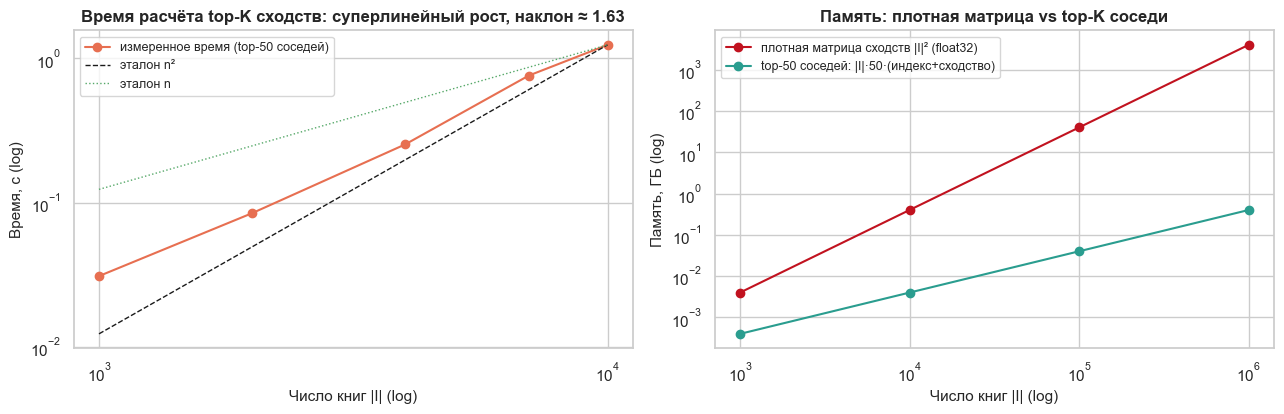

{1000: '0.0 с', 2000: '0.1 с', 4000: '0.3 с', 7000: '0.8 с', 10000: '1.2 с'}


In [26]:
sizes = [1000, 2000, 4000, 7000, 10000]
times = []
rng = np.random.default_rng(SEED)
for n in sizes:
    cols_sub = np.sort(rng.choice(n_items, n, replace=False))
    M_sub = outer.R_seen[:, cols_sub].tocsr()
    t0 = time.perf_counter(); item_neighbors(M_sub, k_max=50); times.append(time.perf_counter() - t0)
slope = np.polyfit(np.log(sizes), np.log(times), 1)[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
ax.plot(sizes, times, "o-", color="#e76f51", label="измеренное время (top-50 соседей)")
ax.plot(sizes, times[-1] * (np.array(sizes) / sizes[-1]) ** 2, "k--", lw=1, label="эталон n²")
ax.plot(sizes, times[-1] * (np.array(sizes) / sizes[-1]), "g:", lw=1, label="эталон n")
ax.set(xscale="log", yscale="log", xlabel="Число книг |I| (log)", ylabel="Время, с (log)", title=f"Время расчёта top-K сходств: суперлинейный рост, наклон ≈ {slope:.2f}")
ax.legend()

ax = axes[1]
grid_i = np.array([1e3, 1e4, 1e5, 1e6])
ax.plot(grid_i, grid_i ** 2 * 4 / 1e9, "o-", color="#c1121f", label="плотная матрица сходств |I|² (float32)")
ax.plot(grid_i, grid_i * 50 * 8 / 1e9, "o-", color="#2a9d8f", label="top-50 соседей: |I|·50·(индекс+сходство)")
ax.set(xscale="log", yscale="log", xlabel="Число книг |I| (log)", ylabel="Память, ГБ (log)", title="Память: плотная матрица vs top-K соседи")
ax.legend()
plt.tight_layout(); plt.show()
print({n: f"{t:.1f} с" for n, t in zip(sizes, times)})

**Результат замера.** Время растёт **суперлинейно** (наклон в log-log заметно больше 1 — на графике), хотя теоретически для плотного случая он стремится к 2:
на малых размерах доминируют накладные расходы, а разреженность смягчает рост. На наших 10⁴ книгах расчёт занимает порядка секунды, но основная проблема масштабирования —
**память плотной матрицы** (0.4 ГБ → 40 ГБ → 4 ТБ) и число пар «книга–книга» при росте каталога и активности пользователей; поэтому на практике хранят только top-K соседей и пересчитывают их оффлайн.

# Этап 4. Матричное разложение: SVD (библиотека `surprise`)
## 4.1 Модель

`surprise.SVD` — это «Funk SVD» с биасами: $\hat r_{ui}=\mu+b_u+b_i+p_u^{\top}q_i$, параметры ($b_u, b_i, p_u, q_i$) обучаются стохастическим градиентным спуском по **наблюдаемым** оценкам
с L2-регуляризацией. Работает за $O(\text{epochs}\cdot m\cdot f)$, где $m$ — число оценок, $f$ — число факторов, и **не требует** матрицы сходств $|I|^2$ — поэтому масштабируется гораздо лучше Item-CF.

Обёртка `SVDRecommender` обучает `surprise.SVD` на train, а затем выносит факторы в массивы numpy, выровненные по нашим индексам: это позволяет предсказывать оценки **векторно** (`μ + b_u + b_i + P·Qᵀ`)
сразу для чанка пользователей и всех книг — вместо 500 млн вызовов `algo.predict` в питоновском цикле.

In [27]:
class SVDRecommender(Recommender):
    name = "SVD (surprise)"

    def __init__(self, train_df, **params):
        dataset = Dataset.load_from_df(train_df[["user_id", "book_id", "rating"]], Reader(rating_scale=(1, 5)))
        self.trainset = dataset.build_full_trainset()
        self.algo = SVD(random_state=SEED, **params)
        self.algo.fit(self.trainset)
        ts, a = self.trainset, self.algo
        self.mu = ts.global_mean
        # выравниваем inner-индексы surprise по нашим индексам; отсутствующие в train пользователи/книги получают нулевые факторы и биасы (как в surprise)
        u_in, i_in = np.array(list(ts.all_users())), np.array(list(ts.all_items()))
        u_pos = np.searchsorted(user_ids, [ts.to_raw_uid(x) for x in u_in])
        i_pos = np.searchsorted(book_ids, [ts.to_raw_iid(x) for x in i_in])
        k = a.pu.shape[1]
        self.bu, self.P = np.zeros(n_users, np.float32), np.zeros((n_users, k), np.float32)
        self.bi, self.Q = np.zeros(n_items, np.float32), np.zeros((n_items, k), np.float32)
        self.bu[u_pos], self.P[u_pos] = a.bu[u_in], a.pu[u_in]
        self.bi[i_pos], self.Q[i_pos] = a.bi[i_in], a.qi[i_in]

    def score(self, users):
        """Предсказанные оценки (без клиппинга — иначе возникают ничьи на значении 5.0) для чанка пользователей × все книги."""
        return self.mu + self.bu[users][:, None] + self.bi[None, :] + self.P[users] @ self.Q.T

    def predict_pairs(self, u, i):
        u, i = np.asarray(u), np.asarray(i)
        return np.clip(self.mu + self.bu[u] + self.bi[i] + (self.P[u] * self.Q[i]).sum(axis=1), 1, 5)

## 4.2 Подбор гиперпараметров по RMSE на validation

Сетка: число факторов × скорость обучения (`lr_all`) × сила L2-регуляризации (`reg_all`), 30 эпох. Обучение на `train_inner`, метрика — RMSE на `val`.

In [28]:
rows_, best_rmse, svd_inner = [], np.inf, None
with timer("подбор SVD"):
    for n_factors in (50, 100):
        for lr in (0.005, 0.01):
            for reg in (0.05, 0.1, 0.15):
                m = SVDRecommender(train_inner, n_factors=n_factors, n_epochs=30, lr_all=lr, reg_all=reg)
                rmse_val = rmse_mae(m.predict_pairs(val.u, val.i), y_val)[0]
                rows_.append({"n_factors": n_factors, "lr_all": lr, "reg_all": reg, "RMSE (val)": rmse_val})
                if rmse_val < best_rmse:
                    best_rmse, svd_inner, SVD_PARAMS = rmse_val, m, dict(n_factors=n_factors, n_epochs=30, lr_all=lr, reg_all=reg)
svd_grid = pd.DataFrame(rows_)
display(svd_grid.pivot_table(index=["n_factors", "lr_all"], columns="reg_all", values="RMSE (val)").round(4))
print("Лучшие параметры SVD:", SVD_PARAMS, f"| RMSE(val) = {best_rmse:.4f}")

⏱ подбор SVD: 156.8 c


reg_all             0.05    0.10    0.15
n_factors lr_all                        
50        0.005   0.8399  0.8384  0.8390
          0.010   0.8450  0.8343  0.8357
100       0.005   0.8430  0.8394  0.8394
          0.010   0.8453  0.8342  0.8350

Лучшие параметры SVD: {'n_factors': 100, 'n_epochs': 30, 'lr_all': 0.01, 'reg_all': 0.1} | RMSE(val) = 0.8342


## 4.3 Финальное обучение и RMSE на test
Обучаем `SVD` на всём `train` и оцениваем на отложенной выборке `test`: официальной метрикой `surprise.accuracy.rmse` (через `algo.test`) и нашей векторной реализацией — значения должны совпасть.

In [29]:
with timer("обучение финального SVD"):
    svd_model = SVDRecommender(train, **SVD_PARAMS)

testset = list(zip(test["user_id"], test["book_id"], test["rating"]))
rmse_surprise = accuracy.rmse(svd_model.algo.test(testset), verbose=False)
y_test, u_test, i_test = test["rating"].to_numpy(), test["u"].to_numpy(), test["i"].to_numpy()
rmse_vec, mae_vec = rmse_mae(svd_model.predict_pairs(u_test, i_test), y_test)
print(f"RMSE на test: surprise = {rmse_surprise:.4f} | векторная реализация = {rmse_vec:.4f} | MAE = {mae_vec:.4f}")
assert abs(rmse_surprise - rmse_vec) < 1e-3

# проверка эквивалентности предсказаний «пара за парой» (surprise) и векторных
chk = np.random.default_rng(SEED).choice(len(test), 1000, replace=False)
p_sur = np.array([svd_model.algo.predict(int(test.user_id.iloc[j]), int(test.book_id.iloc[j])).est for j in chk])
assert np.allclose(p_sur, svd_model.predict_pairs(u_test[chk], i_test[chk]), atol=1e-4)
print("✓ векторные предсказания совпадают с algo.predict")

⏱ обучение финального SVD: 17.2 c


RMSE на test: surprise = 0.8297 | векторная реализация = 0.8297 | MAE = 0.6462
✓ векторные предсказания совпадают с algo.predict


### Сравнение RMSE на test: все «предсказатели оценок»

⏱ Item-CF predictor на train: 2.3 c


,RMSE,MAE
Глобальное среднее,0.9869,0.7898
Среднее по книге,0.9499,0.7634
Среднее по пользователю,0.8936,0.6833
Baseline b_u + b_i,0.8418,0.6567
Item-CF: формула из задания (K=40),0.8874,0.6285
"Item-CF: взвешенное среднее + сжатие (K=20, damp=0.1)",0.8218,0.6174
"Item-CF: baseline-adjusted + сжатие (K=40, damp=0.1)",0.7993,0.6013
SVD (surprise),0.8297,0.6462


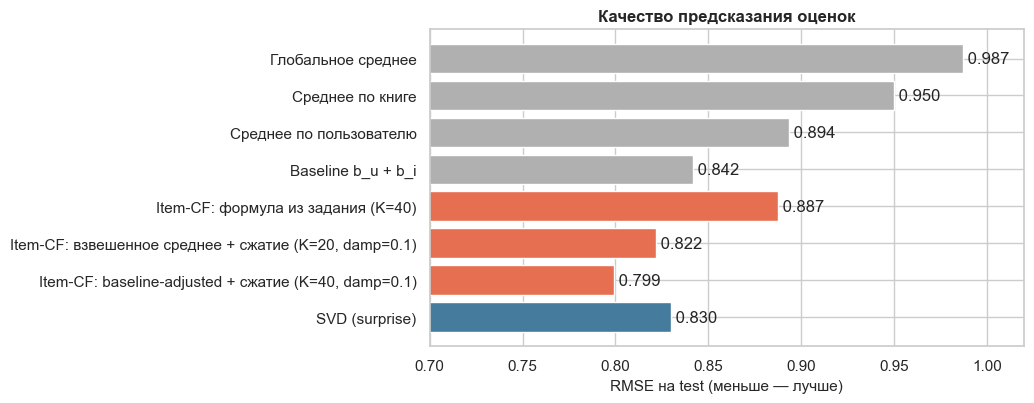

,user_id,book,факт,Item-CF,SVD
0,15035,The Flame and the Flower,3,3.95,4.07
1,37432,The Mystery Knight (The Tales of Dunk and Egg,4,4.55,4.41
2,25048,The World According to Garp,4,4.10,4.31
3,17636,Essentialism: The Disciplined Pursuit of Less,3,3.79,3.84
4,6458,"Ramona the Pest (Ramona, #2)",4,3.93,4.00


In [30]:
with timer("Item-CF predictor на train"):
    icf = ItemCFRatingPredictor(train)

mu_tr = train["rating"].mean()
item_mean = train.groupby("i")["rating"].mean().reindex(range(n_items)).fillna(mu_tr).to_numpy()
user_mean = train.groupby("u")["rating"].mean().reindex(range(n_users)).fillna(mu_tr).to_numpy()
cfg_label = lambda c: f"K={c['k']}" + (f", damp={c['damp']:g}" if c["damp"] else "")
pred_table = {
    "Глобальное среднее": np.full(len(test), mu_tr),
    "Среднее по книге": item_mean[i_test],
    "Среднее по пользователю": user_mean[u_test],
    "Baseline b_u + b_i": icf.baseline(u_test, i_test),
    f"Item-CF: формула из задания ({cfg_label(ICF_CFG['spec'])})": icf.predict_pairs(u_test, i_test, k=ICF_CFG["spec"]["k"], mode="avg"),
    f"Item-CF: взвешенное среднее + сжатие ({cfg_label(ICF_CFG['avg+damp'])})": icf.predict_pairs(u_test, i_test, k=ICF_CFG["avg+damp"]["k"], mode="avg", damp=ICF_CFG["avg+damp"]["damp"]),
    f"Item-CF: baseline-adjusted + сжатие ({cfg_label(ICF_CFG['baseline+damp'])})": icf.predict_pairs(u_test, i_test, k=ICF_CFG["baseline+damp"]["k"], mode="baseline", damp=ICF_CFG["baseline+damp"]["damp"]),
    "SVD (surprise)": svd_model.predict_pairs(u_test, i_test),
}
rmse_table = pd.DataFrame({name: dict(zip(("RMSE", "MAE"), rmse_mae(p, y_test))) for name, p in pred_table.items()}).T
display(rmse_table.style.format("{:.4f}").highlight_min(axis=0, props="font-weight:bold; background-color:#d8f3dc"))

fig, ax = plt.subplots(figsize=(10.5, 4.2))
colors = ["#b0b0b0"] * 4 + ["#e76f51"] * 3 + ["#457b9d"]
ax.barh(rmse_table.index[::-1], rmse_table["RMSE"].values[::-1], color=colors[::-1])
for y_, v in enumerate(rmse_table["RMSE"].values[::-1]):
    ax.text(v, y_, f" {v:.3f}", va="center")
ax.set(xlim=(0.7, 1.02), xlabel="RMSE на test (меньше — лучше)", title="Качество предсказания оценок")
plt.tight_layout(); plt.show()

# пример предсказаний для конкретных пар «пользователь — книга» из test (Item-CF.predict работает в исходных идентификаторах)
ex = test.sample(5, random_state=SEED)
display(pd.DataFrame({"user_id": ex.user_id.values, "book": books.set_index("book_id").loc[ex.book_id, "title"].str[:45].values, "факт": ex.rating.values,
                      "Item-CF": [round(icf.predict(r.user_id, r.book_id, k=ICF_CFG["baseline+damp"]["k"], mode="baseline", damp=ICF_CFG["baseline+damp"]["damp"]), 2) for r in ex.itertuples()],
                      "SVD": svd_model.predict_pairs(ex.u.values, ex.i.values).round(2)}))
del icf                                                                      # освобождаем плотную матрицу сходств (≈ 400 МБ)

**Вывод по предсказанию оценок (RMSE на test).**
* **Смещения решают почти всё.** Глобальное среднее даёт RMSE 0.987, а простая сумма «смещение пользователя + смещение книги» (`b_u + b_i`) — 0.842: основная часть объяснимой дисперсии оценок — это «щедрые/строгие» пользователи и «любимые/нелюбимые» книги.
* **Item-CF по формуле из задания** (чистое взвешенное среднее оценок пользователя по K похожим книгам) — 0.887: лучше «среднего по пользователю» (0.894), но хуже baseline `b_u + b_i`. Причина — шумные сходства: у пары книг в этой выборке очень мало общих оценщиков, и оценка по паре соседей — почти случайна.
* **Сжатие (`damp`) исправляет ситуацию.** Когда соседей мало или они слабо похожи, оценка «тянется» к baseline; взвешенное среднее со сжатием даёт 0.822, а baseline-adjusted с поправкой на смещения — **0.799 (лучший результат)**. MAE у Item-CF также ниже (≈ 0.60 против 0.65 у SVD).
* **SVD (surprise): 0.830** — немного лучше baseline (0.842) и заметно лучше формулы из задания, но уступает Item-CF с поправкой. Вероятная причина — структура данных: у читателей сильные *локальные* связи (части одной серии, книги одного автора получают у одного пользователя похожие оценки), а ≤ 100 латентных факторов такую «мелкую» структуру сглаживают; Item-CF с baseline-поправкой улавливает её напрямую (это объяснение — гипотеза, отдельно мы её не проверяли).
* **Масштабируемость — аргумент в пользу SVD:** он не требует матрицы сходств $|I|^2$, обучается за $O(\text{epochs}\cdot m\cdot f)$ и онлайн считает оценку за $O(f)$. На больших каталогах стандартный выбор — факторизация, а Item-CF используется как локальная поправка к ней (идея `KNNBaseline`/гибридов).
* Гиперпараметры SVD и Item-CF подобраны **на validation**, test использовался один раз для финальной оценки.

## 4.4 `get_recommendations(user_id, N=5)`: Top-N по предсказанному рейтингу
Функция принимает **исходный `user_id`**, векторно считает предсказанные рейтинги для всех книг и возвращает N лучших среди ещё не оценённых пользователем (в train).
Для неизвестного пользователя (холодный старт) возвращается неперсонализированный Top-N.

In [31]:
def get_recommendations(user_id, N=5, model=svd_model, seen=outer.R_seen):
    """Top-N книг с наибольшим предсказанным рейтингом для пользователя (исходный user_id), без уже оценённых книг."""
    u = int(np.searchsorted(user_ids, user_id))
    if u >= n_users or user_ids[u] != user_id:                                   # холодный старт: пользователя нет в данных
        fallback = popular_books(N).rename(columns={"mean_rating": "predicted_rating"})
        return fallback[["book_id", "title", "authors", "predicted_rating"]].assign(note="новый пользователь → популярные книги")
    top = model.recommend(np.array([u]), N, seen[[u]])[0]
    pred = np.clip(model.score(np.array([u]))[0, top], 1, 5)
    return books.iloc[top][["book_id", "title", "authors"]].assign(predicted_rating=pred.round(3)).reset_index(drop=True)


demo_pool = outer.eval_users[(outer.user_support[outer.eval_users] >= 40) & (outer.user_support[outer.eval_users] <= 60)]
demo_u = int(demo_pool[0]); demo_user_id = int(user_ids[demo_u])
print(f"Пользователь {demo_user_id}: {outer.user_support[demo_u]} оценок в train")
display(get_recommendations(demo_user_id, N=5))
display(get_recommendations(10 ** 9, N=3))                                       # неизвестный пользователь

Пользователь 7: 60 оценок в train


,book_id,title,authors,predicted_rating
0,9076,Preach My Gospel: A Guide To Missionary Service,The Church of Jesus Christ of Latter-day Saints,4.641
1,2244,"Saga, Vol. 2 (Saga, #2)","Brian K. Vaughan, Fiona Staples",4.633
2,6920,The Indispensable Calvin and Hobbes,Bill Watterson,4.627
3,2767,"Saga, Vol. 3 (Saga, #3)","Brian K. Vaughan, Fiona Staples",4.612
4,1029,"Saga, Vol. 1 (Saga, #1)","Brian K. Vaughan, Fiona Staples",4.608


,book_id,title,authors,predicted_rating,note
0,6361,There's Treasure Everywhere: A Calvin and Hobbes Collection,Bill Watterson,4.807229,новый пользователь → популярные книги
1,7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem",4.793651,новый пользователь → популярные книги
2,6920,The Indispensable Calvin and Hobbes,Bill Watterson,4.792683,новый пользователь → популярные книги


Возвращаемые книги — в основном произведения с высоким смещением $b_i$ («универсально высоко оцениваемые»), а не обязательно те, что пользователь выберет. Ниже (этап 5) мы увидим, что это **ожидаемое** свойство ранжирования по предсказанной оценке, и разберём его причины.

## 4.5 Дополнительно: неявная матричная факторизация (PureSVD)
`surprise.SVD` обучается только на значениях оценок и ничего не знает о том, **какие книги пользователь вообще выбирал**. Для сравнения добавим PureSVD — усечённое SVD бинарной матрицы взаимодействий (разреженные матричные операции, `randomized_svd`):
$R\approx U\Sigma V^{\top}$, score $=R_u V V^{\top}$. Число факторов подберём на validation.

In [32]:
class PureSVDRecommender(Recommender):
    name = "PureSVD (implicit)"

    def __init__(self, R_seen, n_factors=200):
        _, _, Vt = randomized_svd(R_seen, n_components=n_factors, n_iter=5, random_state=SEED)
        self.R, self.V = R_seen, Vt.T.astype(np.float32)

    def score(self, users):
        return (self.R[users] @ self.V) @ self.V.T


rows_ = []
with timer("подбор PureSVD"):
    for nf in (50, 100, 200, 400):
        res = evaluate(PureSVDRecommender(inner.R_seen, nf), inner, users=val_users, ks=(10,))
        rows_.append({"n_factors": nf, "nDCG@10": res.metrics["nDCG@10"].mean(), "Recall@10": res.metrics["R@10"].mean()})
psvd_grid = pd.DataFrame(rows_).set_index("n_factors")
display(psvd_grid.round(4))
PSVD_FACTORS = int(psvd_grid["nDCG@10"].idxmax())
print("PureSVD: выбрано факторов =", PSVD_FACTORS)

⏱ подбор PureSVD: 18.6 c


,nDCG@10,Recall@10
n_factors,,
50,0.0296,0.0380
100,0.0557,0.0757
200,0.0889,0.1245
400,0.1188,0.1688


PureSVD: выбрано факторов = 400


# Этап 5. Оценка и сравнение моделей
## 5.1 Обучение всех моделей на `train` и оценка на `test`
Все модели обучены только на train (80 % оценок каждого пользователя), оцениваются на **отложенных** 20 %. Добавлены контрольные бейзлайны:
`Random` (нижняя граница), «Popularity (most rated)» (по числу оценок в train) и «Popularity (Goodreads count)» — внешняя статистика `ratings_count` из `books.csv` (диагностика, не из нашей выборки).

In [33]:
def fit_models(data, svd=None, with_psvd=True):
    """Обучает компоненты на данных сплита `data` с выбранными гиперпараметрами."""
    fb = {"like": data.R_like, "seen": data.R_seen}[KNN_PARAMS["feedback"]]
    prior = (fb.sum(axis=0).A1 / max(fb.sum(axis=0).A1.max(), 1)).astype(np.float32)
    neighbors = item_neighbors(fb, k_max=KNN_PARAMS["k"], shrink=KNN_PARAMS["shrink"])
    zoo = {"knn": ItemKNNRecommender(neighbors, fb, k=KNN_PARAMS["k"], prior=prior),
           "content": ContentBasedRecommender(X, data.R_like),
           "svd": svd if svd is not None else SVDRecommender(data.train_df, **SVD_PARAMS)}
    if with_psvd:
        zoo["psvd"] = PureSVDRecommender(data.R_seen, PSVD_FACTORS)
    return zoo


with timer("обучение всех моделей"):
    zoo = fit_models(outer, svd=svd_model)

models = {
    "Random": RandomRecommender(),
    "Popularity (mean rating)": pop_mean,
    "Popularity (most rated)": pop_count,
    "Popularity (Goodreads count)": pop_goodreads,
    "Content-based (TF-IDF)": zoo["content"],
    "Item-based CF": zoo["knn"],
    "SVD (surprise)": zoo["svd"],
    "PureSVD (implicit)": zoo["psvd"],
}
results = {}
for name, model in models.items():
    with timer(f"оценка: {name}"):
        results[name] = evaluate(model, outer)
print(f"\nОценка на {len(outer.eval_users):,} пользователях (у каждого ≥ 1 релевантная отложенная книга, оценка ≥ {RELEVANCE_THRESHOLD})")

⏱ обучение всех моделей: 9.9 c


⏱ оценка: Random: 5.4 c


⏱ оценка: Popularity (mean rating): 6.6 c


⏱ оценка: Popularity (most rated): 6.9 c


⏱ оценка: Popularity (Goodreads count): 7.0 c


⏱ оценка: Content-based (TF-IDF): 14.8 c


⏱ оценка: Item-based CF: 5.4 c


⏱ оценка: SVD (surprise): 6.8 c


⏱ оценка: PureSVD (implicit): 6.7 c

Оценка на 42,523 пользователях (у каждого ≥ 1 релевантная отложенная книга, оценка ≥ 4)


## 5.2 Сводная таблица метрик (K = 5, 10, 20)

In [34]:
summary = summary_table(results)
show_table(summary)

### Таблица с доверительными интервалами для K = 10 (среднее ± 95 % ДИ по пользователям)

In [35]:
ci_table = pd.DataFrame({name: {f"{lab}@{MAIN_K}": f"{r.metrics[f'{m}@{MAIN_K}'].mean():.4f} ± {ci95(r.metrics[f'{m}@{MAIN_K}']):.4f}"
                                for lab, m in (("Precision", "P"), ("Recall", "R"), ("nDCG", "nDCG"))} for name, r in results.items()}).T
display(ci_table)

,Precision@10,Recall@10,nDCG@10
Random,0.0003 ± 0.0001,0.0011 ± 0.0003,0.0006 ± 0.0001
Popularity (mean rating),0.0004 ± 0.0001,0.0018 ± 0.0003,0.0010 ± 0.0002
Popularity (most rated),0.0001 ± 0.0000,0.0003 ± 0.0001,0.0002 ± 0.0001
Popularity (Goodreads count),0.0006 ± 0.0001,0.0002 ± 0.0000,0.0006 ± 0.0001
Content-based (TF-IDF),0.0367 ± 0.0007,0.1586 ± 0.0031,0.1167 ± 0.0023
Item-based CF,0.0724 ± 0.0011,0.2720 ± 0.0036,0.2174 ± 0.0030
SVD (surprise),0.0006 ± 0.0001,0.0018 ± 0.0003,0.0011 ± 0.0002
PureSVD (implicit),0.0602 ± 0.0011,0.1830 ± 0.0031,0.1432 ± 0.0024


## 5.3 Визуализация сравнения

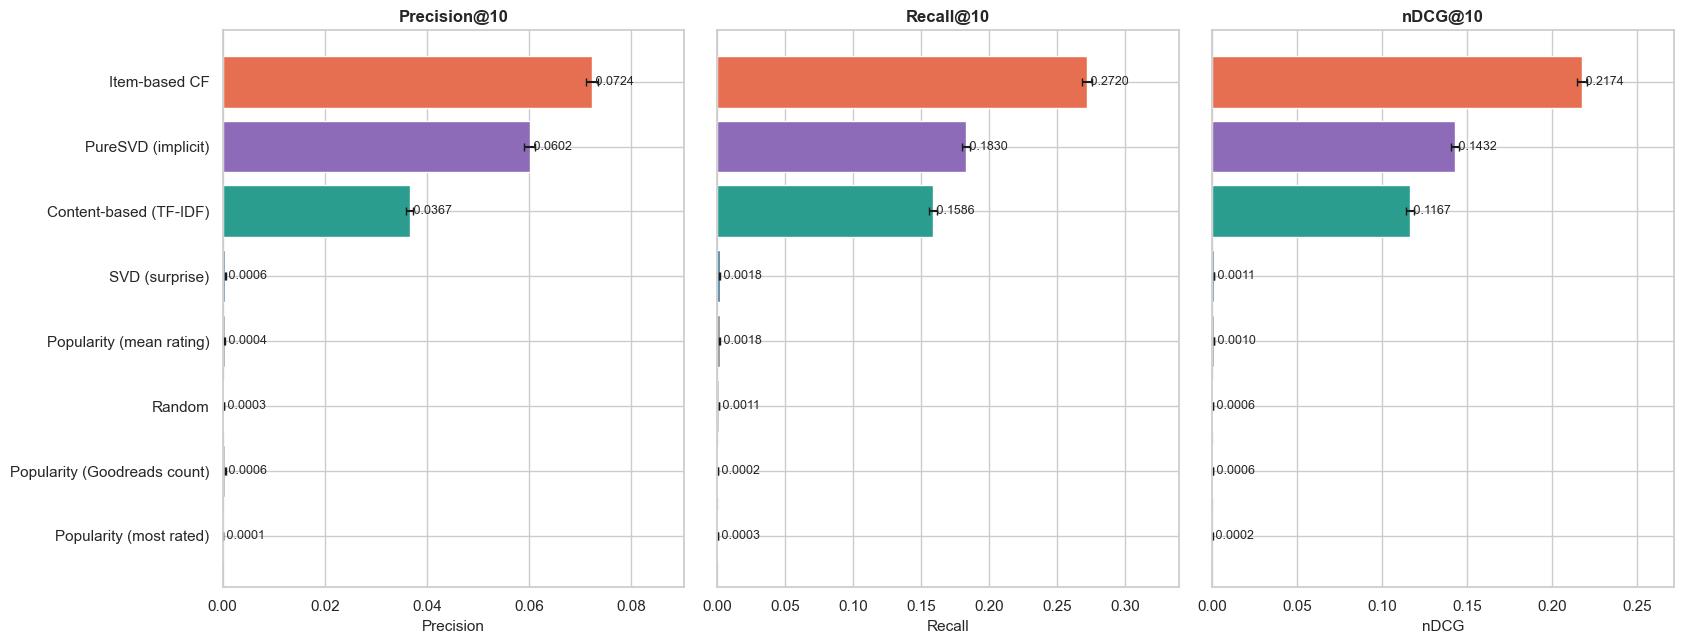

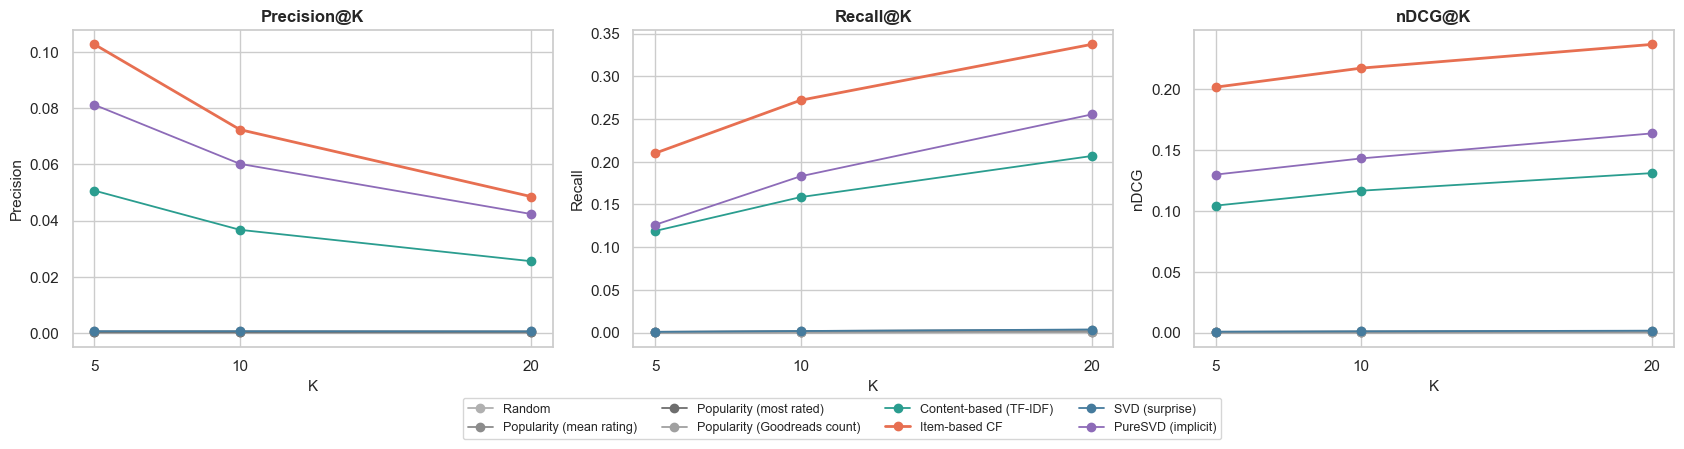

In [36]:
def plot_model_comparison(results, k=MAIN_K, title_suffix=""):
    fig, axes = plt.subplots(1, 3, figsize=(17, 0.55 * len(results) + 2.2), sharey=True)
    order = sorted(results, key=lambda n: results[n].metrics[f"nDCG@{k}"].mean())
    for ax, (label, m) in zip(axes, (("Precision", "P"), ("Recall", "R"), ("nDCG", "nDCG"))):
        vals = [results[n].metrics[f"{m}@{k}"].mean() for n in order]
        errs = [ci95(results[n].metrics[f"{m}@{k}"]) for n in order]
        ax.barh(order, vals, xerr=errs, color=[MODEL_COLORS.get(n, "#999") for n in order], capsize=3)
        for y_, v in enumerate(vals):
            ax.text(v, y_, f" {v:.4f}", va="center", fontsize=9)
        ax.set(title=f"{label}@{k}{title_suffix}", xlabel=label, xlim=(0, max(vals) * 1.25))
    plt.tight_layout(); plt.show()


plot_model_comparison(results)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, (label, m) in zip(axes, (("Precision", "P"), ("Recall", "R"), ("nDCG", "nDCG"))):
    for name, r in results.items():
        ax.plot(KS, [r.metrics[f"{m}@{k}"].mean() for k in KS], "o-", label=name, color=MODEL_COLORS.get(name), lw=2 if "CF" in name else 1.3)
    ax.set(xlabel="K", ylabel=label, title=f"{label}@K", xticks=KS)
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="lower center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.08))
plt.tight_layout(); plt.show()

## 5.4 Покрытие каталога и смещение популярности рекомендаций
Точность — не единственный критерий: показываем, насколько **разнообразны** списки (покрытие каталога@10 — доля книг, попавших хотя бы в один список) и «насколько популярны» рекомендуемые книги
(средний перцентиль по глобальной популярности Goodreads: 1.0 — самые популярные).

In [37]:
pop_percentile = books["ratings_count"].rank(pct=True).to_numpy()
div = pd.DataFrame({name: {f"Coverage@{MAIN_K}": np.unique(r.recs[:, :MAIN_K]).size / n_items,
                           "доля рекомендаций из топ-10 % популярных": (pop_percentile[r.recs[:, :MAIN_K]] > 0.9).mean(),
                           "средний перцентиль популярности": pop_percentile[r.recs[:, :MAIN_K]].mean()} for name, r in results.items()}).T
display(div.style.format("{:.3f}"))

,Coverage@10,доля рекомендаций из топ-10 % популярных,средний перцентиль популярности
Random,1.000,0.100,0.500
Popularity (mean rating),0.002,0.000,0.268
Popularity (most rated),0.001,0.000,0.553
Popularity (Goodreads count),0.003,1.000,1.000
Content-based (TF-IDF),0.932,0.167,0.563
Item-based CF,0.964,0.032,0.425
SVD (surprise),0.045,0.024,0.437
PureSVD (implicit),0.793,0.034,0.481


## 5.5 Проверка на утечку данных (негативный контроль)
Если бы метрики Item-CF были завышены из-за утечки, перемешивание пользовательских профилей их не разрушило бы. Подадим модели **профили чужих пользователей** (случайная перестановка строк матрицы истории):
качество должно упасть до уровня случайного.

In [38]:
perm = np.random.default_rng(SEED).permutation(len(outer.eval_users))
users_c = outer.eval_users[:6000]
shuffled_scores = np.vstack([zoo["knn"].score(outer.eval_users[perm][s:s + 2000]) for s in range(0, 6000, 2000)])   # профиль «чужого» пользователя
recs_c = np.vstack([top_k(shuffled_scores[s:s + 2000], outer.R_seen[users_c[s:s + 2000]], 10) for s in range(0, 6000, 2000)])
ctrl = metrics_from_recs(recs_c, users_c, outer.rel, ks=(10,))
print(f"Item-CF с перемешанными профилями: nDCG@10 = {ctrl['nDCG@10'].mean():.4f}, Recall@10 = {ctrl['R@10'].mean():.4f}  "
      f"(настоящие профили: {results['Item-based CF'].metrics['nDCG@10'][:6000].mean():.4f} / {results['Item-based CF'].metrics['R@10'][:6000].mean():.4f})")

Item-CF с перемешанными профилями: nDCG@10 = 0.0007, Recall@10 = 0.0012  (настоящие профили: 0.1768 / 0.2160)


## 5.6 Интерпретация результатов

**Что показывают таблицы и графики (test, 42 523 пользователя, K = 5/10/20).**

1. **Лучшая модель по всем метрикам и всем K — Item-based CF:** Precision@10 ≈ 0.072, Recall@10 ≈ 0.272 (в Top-10 попадает больше четверти того, что пользователь позже высоко оценит), nDCG@10 ≈ 0.217 — в сотни раз выше случайного (≈ 0.0006). Доверительные интервалы узкие (± 0.001–0.004), поэтому различия между моделями статистически значимы. Порядок моделей: **Item-CF > PureSVD > Content-based ≫ Popularity ≈ SVD (по предсказанной оценке) ≈ Random**.
2. **Почему Item-CF так силён именно здесь.** Интересы читателей локальны: серии (Harry Potter — 7 книг), авторы и тематические кластеры. Пользователь, оценивший 1–2 книги серии, с высокой вероятностью прочитает остальные, а Item-CF прямо использует сигнал «те, кто читал X, читали и Y». Достаточно 1–2 оценок: на сегменте пользователей с 1–2 оценками nDCG@10 ≈ 0.18 при среднем по всем ≈ 0.22 (см. график сегментов в 6.1). **Негативный контроль 5.5** (профили пользователей перемешаны) обваливает качество до уровня случайного (nDCG@10 ≈ 0.0007), т.е. утечки нет: высокие значения — свойство данных, а не ошибка протокола.
3. **Popularity ≈ Random — это не баг, а особенность выборки.** (а) В `ratings.csv` на каждую книгу приходится ≈ 100 оценок (EDA 1.5), поэтому популярность *внутри выборки* почти равномерна; (б) «лучшие» по среднему рейтингу книги (Calvin & Hobbes, подарочные наборы) одинаковы для всех, покрытие каталога ≈ 0.2 % (во всех списках встречается лишь ≈ 20 разных книг из 10 000), а вероятность, что именно эти 10 книг прочитает и высоко оценит конкретный человек, мала; (в) диагностический бейзлайн по реальной популярности Goodreads (`ratings_count`) тоже ≈ 0.0006 — то есть дело не в нашем пороге. Бейзлайн полезен как «нижняя планка» и как запасной вариант для пользователя без истории.
4. **SVD по предсказанной оценке ≈ Random в Top-N, хотя по RMSE он хорош.** Модель обучена предсказывать оценку *уже прочитанных* книг и ничего не знает о том, *какие книги пользователь вообще выбирает* (данные «missing not at random»). Ранжирование по предсказанной оценке выдвигает универсально высоко оцениваемые книги с большим смещением $b_i$ — покрытие каталога лишь ≈ 4.5 % против ≈ 96 % у Item-CF. Это известное явление (Cremonesi et al., 2010): *хорошая модель оценок ≠ хороший ранжировщик*. Подтверждение «от противного» — **PureSVD**, родственный метод (усечённое SVD) по матрице факта взаимодействия: nDCG@10 ≈ 0.143 против ≈ 0.001. Проблема, судя по всему, в **цели обучения**, а не в факторизации как таковой (оговорка: PureSVD отличается от `surprise.SVD` не только данными, но и отсутствием смещений и способом обучения). PureSVD растёт с числом факторов (50 → 400: 0.030 → 0.119 на validation) — «хвостовая» структура требует сотен факторов, что, вероятно, и позволяет Item-CF её опережать.
5. **Content-based** (nDCG@10 ≈ 0.117) вдвое слабее Item-CF, но он не требует оценок других пользователей, т.е. годится для новых книг (эксперимент 6.3) и даёт объяснимые рекомендации.
6. **Форма кривых:** при росте K Precision падает, а Recall и nDCG растут — ожидаемо; порядок моделей одинаков на всех K, значит вывод не зависит от выбранного K.
7. **Разнообразие (5.4):** Item-CF покрывает ≈ 96 % каталога и не смещён к хитам (средний перцентиль популярности 0.43), Popularity и SVD — менее 5 %. (Оговорка: в нашей выборке реальная популярность «сплющена» ограничением в 100 оценок на книгу.)
8. **Оговорка об абсолютных числах.** Метрики считаются по отложенным *наблюдаемым* оценкам ≥ 4: непрочитанные книги не считаются релевантными, хотя могли бы понравиться (unobserved ≠ irrelevant), поэтому абсолютные значения занижены, а сравнение моделей между собой корректно.

# Этап 6. Гибридизация и выводы
## 6.1 Что умеет и чего не умеет каждая модель

| Ситуация | Popularity | Content-based | Item-CF | SVD (explicit) |
|---|---|---|---|---|
| Новый пользователь (0 оценок) | ✅ единственный вариант | ❌ нет профиля | ❌ нет истории | ❌ нет факторов |
| Пользователь с 1–4 оценками | ✅ но без персонализации | ⚠️ профиль из 1–3 книг | ⚠️ работает на сильных сигналах (серии, авторы) | ❌ факторы почти не обучены |
| Новая книга (0 оценок) | ❌ нет статистики | ✅ по названию и тегам | ❌ нет соседей | ❌ нулевые факторы |
| Книга с богатой историей оценок | – | ⚠️ только метаданные | ✅ лучший источник сходства | ✅ факторы хорошо обучены |
| Предсказание значения рейтинга (RMSE) | – | – | ✅ лучший результат с поправкой на смещения и сжатием (0.799); без поправки — слабый | ✅ 0.830, масштабируется лучше |
| Top-N по предсказанной оценке | – | – | – | ❌ почти случайный (см. 5.6) |

Посмотрим, как качество зависит от длины истории пользователя — это определяет логику переключения в гибриде.

,Random,Popularity (mean rating),Content-based (TF-IDF),Item-based CF,SVD (surprise),PureSVD (implicit),пользователей
1–2,0.0005,0.0013,0.1150,0.1847,0.0010,0.0542,9397
3–5,0.0003,0.0008,0.1333,0.2207,0.0005,0.1034,6549
6–10,0.0006,0.0005,0.1211,0.2098,0.0006,0.1319,6963
11–20,0.0006,0.0011,0.1102,0.2180,0.0011,0.1634,8407
21–50,0.0008,0.0013,0.1105,0.2331,0.0016,0.2087,7870
51+,0.0012,0.0011,0.1100,0.2804,0.0024,0.2900,3337


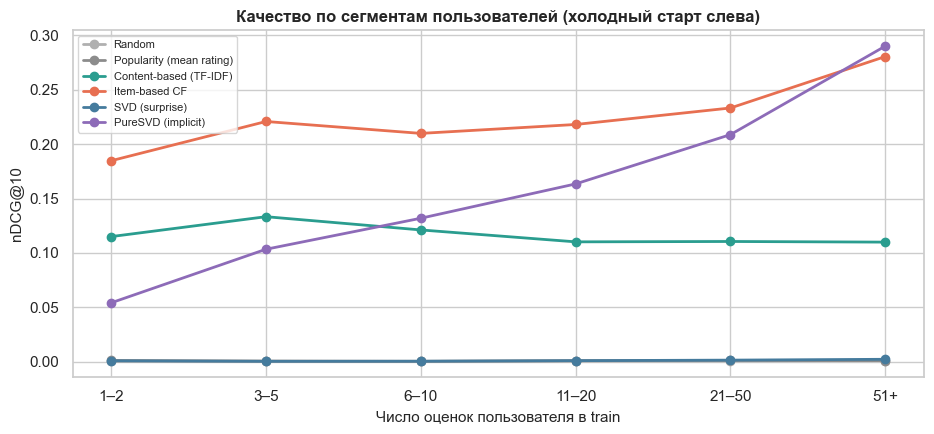

In [39]:
def segment_ndcg(results, support, k=MAIN_K, bins=(0, 2, 5, 10, 20, 50, np.inf), names=("1–2", "3–5", "6–10", "11–20", "21–50", "51+")):
    out = {}
    for name, r in results.items():
        seg_idx = pd.cut(support[r.users], bins=bins, labels=names)
        out[name] = pd.Series(r.metrics[f"nDCG@{k}"]).groupby(seg_idx.to_numpy(), observed=True).mean()
    counts = pd.Series(1, index=seg_idx.to_numpy()).groupby(level=0, observed=True).size()
    return pd.DataFrame(out).reindex(names), counts.reindex(names)


seg_df, seg_counts = segment_ndcg({k: v for k, v in results.items() if k not in ("Popularity (most rated)", "Popularity (Goodreads count)")}, outer.user_support)
display(seg_df.round(4).assign(**{"пользователей": seg_counts.values}))

fig, ax = plt.subplots(figsize=(9.5, 4.5))
for name in seg_df.columns:
    ax.plot(seg_df.index, seg_df[name], "o-", label=name, color=MODEL_COLORS.get(name), lw=2)
ax.set(xlabel="Число оценок пользователя в train", ylabel=f"nDCG@{MAIN_K}", title="Качество по сегментам пользователей (холодный старт слева)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6.2 Предлагаемая гибридная стратегия

**Логика трёх уровней** (всё считается по `z`-нормированным оценкам книг каждого пользователя, чтобы шкалы разных моделей стали сопоставимыми):

1. **Новый пользователь (нет истории)** → неперсонализированный Top-N (Popularity со сглаживанием) + онбординг (попросить выбрать любимые жанры/книги — после 1–2 оценок включаются уровни 2–3).
2. **Известные книги, пользователь с историей** → *взвешенный бленд* `z(Item-CF) + w_c·z(Content) + w_s·z(SVD)`: Item-CF — главный источник «что читают такие же люди»,
   контент разрешает ничьи и подсказывает книги из той же серии/жанра, SVD вносит оценку «понравится ли» (сигнал качества).
3. **Новые книги (почти нет оценок, `n_ratings < 5`)** → CF-модели их не видят, поэтому им **резервируются слоты** в выдаче (например, 2 из 10), которые заполняет контентная модель
   (сходство описания/тегов новой книги с профилем вкуса пользователя). По мере накопления оценок книга «переезжает» в уровень 2.

Веса `w_c`, `w_s` подберём на validation (модели обучены на `train_inner`); слоты для новинок — управляемый компромисс «точность ↔ исследование нового», его цену измерим экспериментом.

In [40]:
def zscore(s):
    s = np.asarray(s, dtype=np.float32)
    return (s - s.mean(axis=1, keepdims=True)) / (s.std(axis=1, keepdims=True) + 1e-9)


class HybridRecommender(Recommender):
    name = "Hybrid"

    def __init__(self, knn, content, svd, pop_scores, item_support, weights, cold_min=5, cold_slots=0, name="Hybrid"):
        self.knn, self.content, self.svd = knn, content, svd
        self.pop, self.w = np.asarray(pop_scores, np.float32), weights
        self.is_cold = item_support < cold_min                          # «новые» книги: слишком мало оценок для CF
        self.cold_slots, self.name = cold_slots, name

    def warm_score(self, users):
        s = zscore(self.knn.score(users)) + self.w["content"] * zscore(self.content.score(users))
        if self.w["svd"]:
            s += self.w["svd"] * zscore(self.svd.score(users))
        s[:, self.is_cold] = -np.inf                                    # новинки попадают в выдачу только через зарезервированные слоты
        return s

    def recommend(self, users, k, seen):
        top = top_k(self.warm_score(users), seen, k - self.cold_slots)
        if self.cold_slots:
            s = np.array(self.content.score(users), dtype=np.float32); s[:, ~self.is_cold] = -np.inf
            top = np.hstack([top, top_k(s, seen, self.cold_slots)])
        no_history = np.diff(seen.indptr) == 0                          # уровень 1: пользователь без истории → популярное
        if no_history.any():
            top[no_history] = top_k(np.broadcast_to(self.pop, (int(no_history.sum()), n_items)), seen[no_history], k)
        return top

### Подбор весов бленда на validation

⏱ компоненты на train_inner: 0.9 c


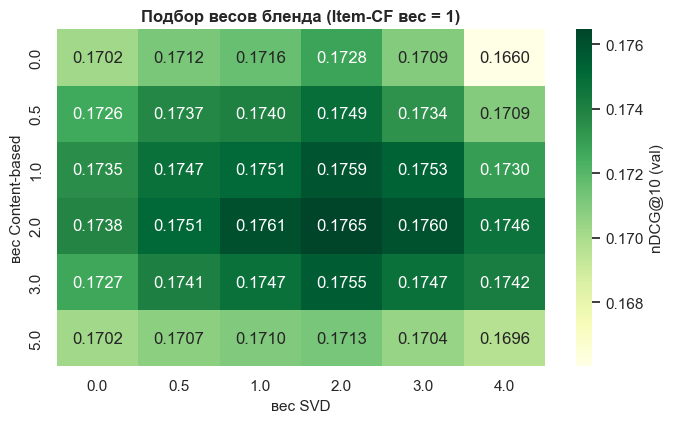

Выбранные веса: {'content': 2.0, 'svd': 2.0} | nDCG@10 (val) Item-CF-only = 0.1702 → бленд = 0.1765


In [41]:
with timer("компоненты на train_inner"):
    zoo_inner = fit_models(inner, svd=svd_inner, with_psvd=False)
Z = {name: zscore(zoo_inner[name].score(val_users)) for name in ("knn", "content", "svd")}
seen_val, rel_val = inner.R_seen[val_users], inner.rel[val_users].toarray().astype(bool)

rows_ = []
for w_c in (0, 0.5, 1, 2, 3, 5):
    for w_s in (0, 0.5, 1, 2, 3, 4):
        top = top_k(Z["knn"] + w_c * Z["content"] + w_s * Z["svd"], seen_val, MAIN_K)
        rows_.append({"w_content": w_c, "w_svd": w_s, f"nDCG@{MAIN_K}": ranking_metrics(top, rel_val, (MAIN_K,))[f"nDCG@{MAIN_K}"].mean()})
w_grid = pd.DataFrame(rows_)
best_w = w_grid.sort_values(f"nDCG@{MAIN_K}", ascending=False).iloc[0]
HYB_W = {"content": float(best_w["w_content"]), "svd": float(best_w["w_svd"])}
fig, ax = plt.subplots(figsize=(7, 4.4))
sns.heatmap(w_grid.pivot(index="w_content", columns="w_svd", values=f"nDCG@{MAIN_K}"), annot=True, fmt=".4f", cmap="YlGn", ax=ax, cbar_kws={"label": f"nDCG@{MAIN_K} (val)"})
ax.set(title="Подбор весов бленда (Item-CF вес = 1)", xlabel="вес SVD", ylabel="вес Content-based")
plt.tight_layout(); plt.show()
print("Выбранные веса:", HYB_W, "| nDCG@10 (val) Item-CF-only =", round(float(w_grid.query("w_content == 0 and w_svd == 0")[f"nDCG@{MAIN_K}"].iloc[0]), 4),
      "→ бленд =", round(float(best_w[f"nDCG@{MAIN_K}"]), 4))
del zoo_inner, Z

### Оценка гибрида на `test` и сравнение со всеми моделями

⏱ оценка Hybrid: 26.6 c
ИТОГОВАЯ СВОДНАЯ ТАБЛИЦА (test, лучшее выделено)


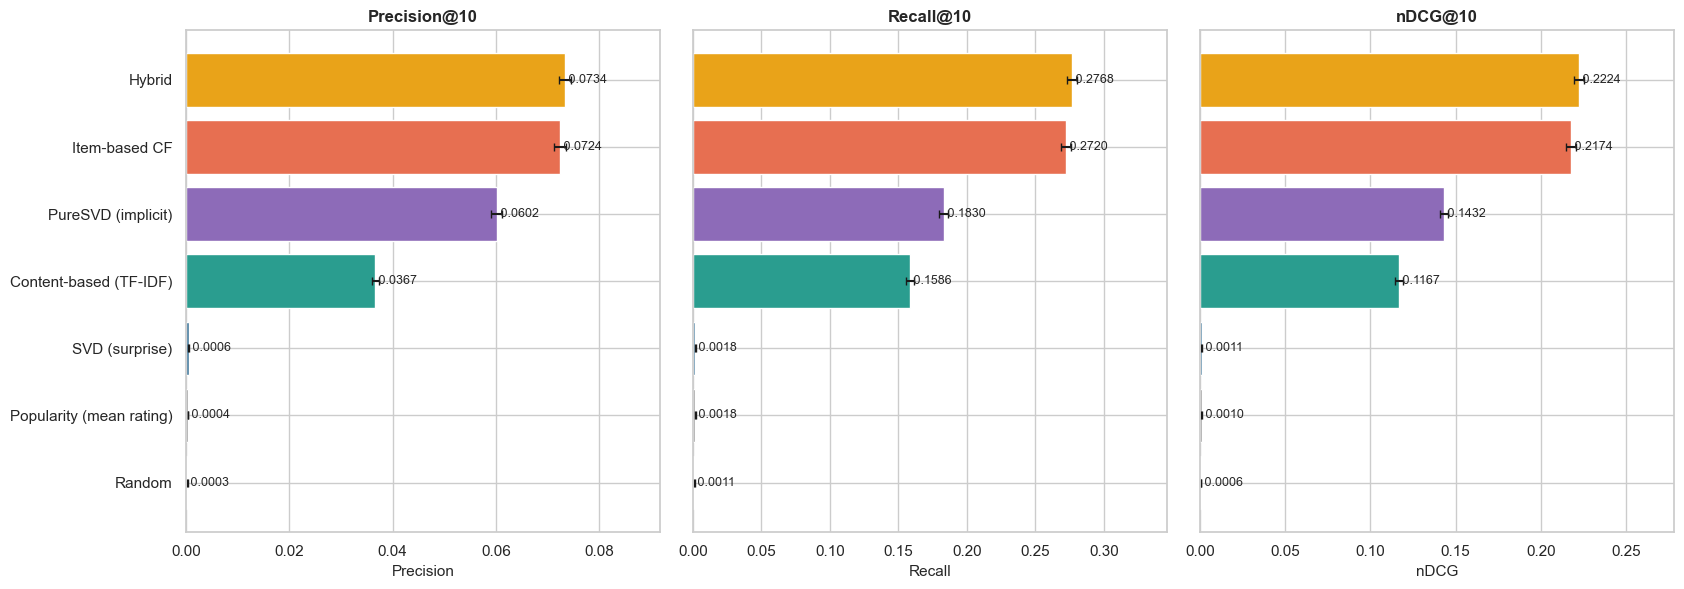

Парная разность nDCG@10 (Hybrid − Item-CF): +0.0050 ± 0.0009 (95 % ДИ по пользователям) → значимо


In [42]:
pop_bayes = popularity_scores(train, "bayes")
hybrid = HybridRecommender(zoo["knn"], zoo["content"], zoo["svd"], pop_bayes, outer.item_support, HYB_W)
with timer("оценка Hybrid"):
    results["Hybrid"] = evaluate(hybrid, outer)

final_names = ["Random", "Popularity (mean rating)", "Content-based (TF-IDF)", "Item-based CF", "SVD (surprise)", "PureSVD (implicit)", "Hybrid"]
final_results = {n: results[n] for n in final_names}
print("ИТОГОВАЯ СВОДНАЯ ТАБЛИЦА (test, лучшее выделено)")
show_table(summary_table(final_results))
plot_model_comparison(final_results)

d = results["Hybrid"].metrics[f"nDCG@{MAIN_K}"] - results["Item-based CF"].metrics[f"nDCG@{MAIN_K}"]
print(f"Парная разность nDCG@{MAIN_K} (Hybrid − Item-CF): {d.mean():+.4f} ± {ci95(d):.4f} (95 % ДИ по пользователям) → "
      f"{'значимо' if abs(d.mean()) > ci95(d) else 'незначимо'}")

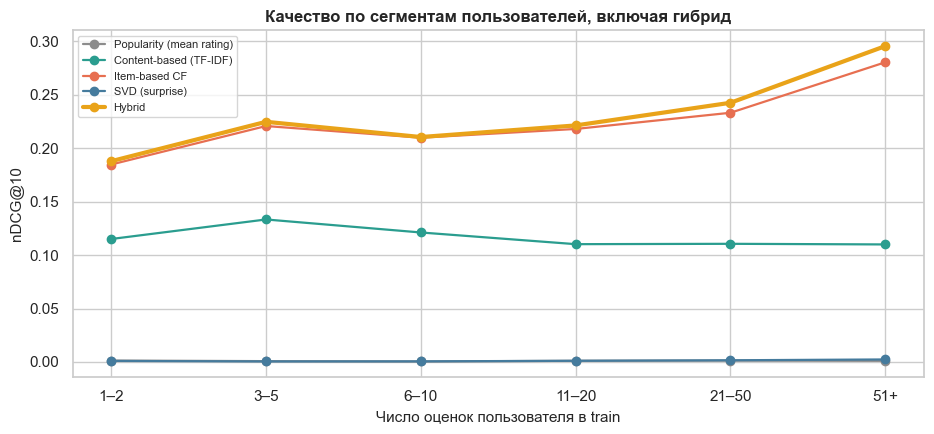

In [43]:
seg_df2, seg_counts2 = segment_ndcg({k: final_results[k] for k in ("Popularity (mean rating)", "Content-based (TF-IDF)", "Item-based CF", "SVD (surprise)", "Hybrid")}, outer.user_support)
fig, ax = plt.subplots(figsize=(9.5, 4.5))
for name in seg_df2.columns:
    ax.plot(seg_df2.index, seg_df2[name], "o-", label=name, color=MODEL_COLORS.get(name), lw=3 if name == "Hybrid" else 1.6)
ax.set(xlabel="Число оценок пользователя в train", ylabel=f"nDCG@{MAIN_K}", title="Качество по сегментам пользователей, включая гибрид")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6.3 Эксперимент «холодные книги»: оправдание слотов для новинок

В основном сплите у всех книг есть оценки, поэтому преимущество контентного уровня гибрида там не видно. Смоделируем **появление новых книг**: случайные 10 % каталога (1000 книг) объявляем «новыми» —
**вырезаем все их оценки из train** и переобучаем все модели; в test остаются оценки этих книг (нужно угадать, какие новинки понравятся пользователю).

* **Сценарий A (пул только из новинок).** Все модели ранжируют только 1000 новых книг: чистая оценка способности работать с холодными книгами. Для случайного выбора 10 книг из 1000 Recall@10 ≈ 10/1000 = 0.01 — это нижняя граница.
* **Сценарий B (весь каталог).** Реалистичный режим: гибрид с `s` слотами для новинок против «чистых» CF-моделей; смотрим общий nDCG@10 и Recall@10 *по новинкам* (какая доля релевантных новинок найдена).

In [44]:
rng = np.random.default_rng(SEED + 7)
cold_items = np.sort(rng.choice(n_items, int(0.1 * n_items), replace=False))
is_cold_item = np.zeros(n_items, dtype=bool); is_cold_item[cold_items] = True
cold_split = SplitData(train[~is_cold_item[train.i.to_numpy()]], test)                  # ни одной оценки «новых» книг в обучении
assert cold_split.item_support[is_cold_item].sum() == 0
rel_cold = (cold_split.rel @ sp.diags(is_cold_item.astype(np.float32))).tocsr()        # релевантные отложенные оценки только новинок
users_cold = users_with_relevant(rel_cold)
print(f"Новых книг: {is_cold_item.sum()} | оценок новинок в train: 0 | пользователей с релевантной новинкой в test: {len(users_cold):,} "
      f"| релевантных оценок новинок: {int(rel_cold.sum()):,} из {int(cold_split.rel.sum()):,}")

with timer("переобучение на данных без новинок"):
    zoo_c = fit_models(cold_split, with_psvd=False)
users_a = np.sort(np.random.default_rng(SEED).choice(users_cold, min(8000, len(users_cold)), replace=False))


class RestrictTo(Recommender):
    """Ранжирует только разрешённые книги; ничьи (например, нулевые score CF у новинок) разрешаются случайным шумом."""

    def __init__(self, model, allowed, name, seed=SEED):
        self.model, self.allowed, self.name, self.rng = model, allowed, name, np.random.default_rng(seed)

    def recommend(self, users, k, seen):
        s = np.array(self.model.score(users), dtype=np.float32)
        s += 1e-5 * self.rng.random(s.shape, dtype=np.float32)
        s[:, ~self.allowed] = -np.inf
        return top_k(s, seen, k)


pool = {"Random": RandomRecommender(), "Item-based CF": zoo_c["knn"], "SVD (surprise)": zoo_c["svd"], "Content-based (TF-IDF)": zoo_c["content"]}
res_a = {n: evaluate(RestrictTo(m, is_cold_item, n), cold_split, users=users_a, rel=rel_cold) for n, m in pool.items()}
cold_a = pd.DataFrame({n: {f"Precision@{MAIN_K}": r.metrics[f"P@{MAIN_K}"].mean(), f"Recall@{MAIN_K}": r.metrics[f"R@{MAIN_K}"].mean(),
                           f"nDCG@{MAIN_K}": r.metrics[f"nDCG@{MAIN_K}"].mean()} for n, r in res_a.items()}).T
print("Сценарий A: ранжирование только новых книг")
show_table(cold_a)

Новых книг: 1000 | оценок новинок в train: 0 | пользователей с релевантной новинкой в test: 9,543 | релевантных оценок новинок: 12,574 из 126,239


⏱ переобучение на данных без новинок: 16.7 c


Сценарий A: ранжирование только новых книг


,Precision@10,Recall@10,nDCG@10
Random,0.0013,0.0097,0.0047
Item-based CF,0.0013,0.0097,0.0047
SVD (surprise),0.0013,0.0096,0.0047
Content-based (TF-IDF),0.0392,0.3099,0.1979


Сценарий B: весь каталог, 10 % книг — новинки без оценок


,nDCG@10 (все книги),Recall@10 (все книги),Recall@10 по новинкам,доля новинок в выдаче
Item-based CF,0.1972,0.2450,0.0000,0.0000
SVD (surprise),0.0012,0.0021,0.0000,0.0000
Content-based (TF-IDF),0.1120,0.1567,0.1340,0.1177
"Hybrid, 0 слот(а) новинок",0.2022,0.2498,0.0000,0.0000
"Hybrid, 1 слот(а) новинок",0.2028,0.2534,0.0896,0.0986
"Hybrid, 2 слот(а) новинок",0.2010,0.2492,0.1498,0.1972
"Hybrid, 3 слот(а) новинок",0.1977,0.2416,0.1826,0.2958


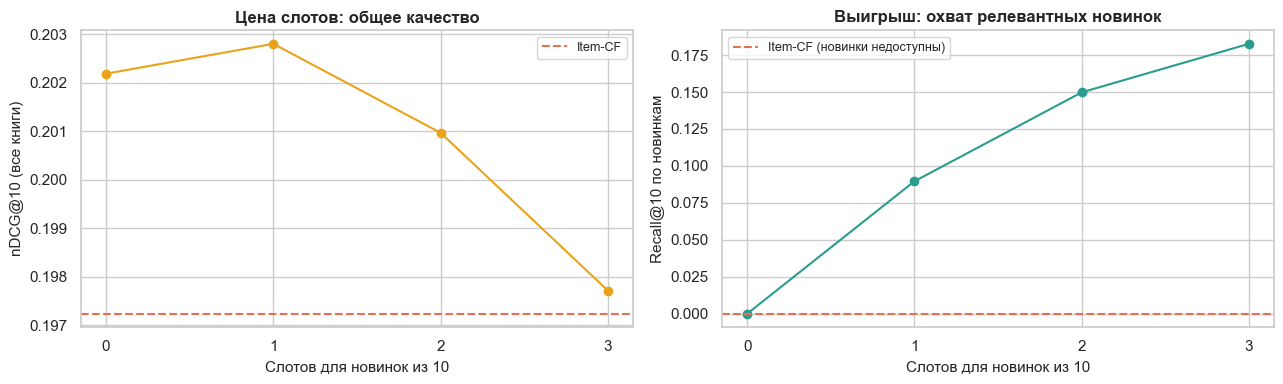

In [45]:
users_b = np.sort(np.random.default_rng(SEED + 1).choice(cold_split.eval_users, 8000, replace=False))
has_cold = np.diff(rel_cold.indptr)[users_b] > 0
variants = {"Item-based CF": zoo_c["knn"], "SVD (surprise)": zoo_c["svd"], "Content-based (TF-IDF)": zoo_c["content"]}
for slots in (0, 1, 2, 3):
    variants[f"Hybrid, {slots} слот(а) новинок"] = HybridRecommender(zoo_c["knn"], zoo_c["content"], zoo_c["svd"], popularity_scores(cold_split.train_df, "bayes"),
                                                                    cold_split.item_support, HYB_W, cold_min=5, cold_slots=slots)
rows_ = {}
for name, model in variants.items():
    recs = get_recommendations_batch(model, cold_split, users_b, MAIN_K)
    overall = metrics_from_recs(recs, users_b, cold_split.rel, ks=(MAIN_K,))
    cold_m = metrics_from_recs(recs[has_cold], users_b[has_cold], rel_cold, ks=(MAIN_K,))
    rows_[name] = {f"nDCG@{MAIN_K} (все книги)": overall[f"nDCG@{MAIN_K}"].mean(), f"Recall@{MAIN_K} (все книги)": overall[f"R@{MAIN_K}"].mean(),
                   f"Recall@{MAIN_K} по новинкам": cold_m[f"R@{MAIN_K}"].mean(), "доля новинок в выдаче": np.isin(recs, cold_items).mean()}
cold_b = pd.DataFrame(rows_).T
print("Сценарий B: весь каталог, 10 % книг — новинки без оценок")
display(cold_b.style.format("{:.4f}").highlight_max(axis=0, props="font-weight:bold; background-color:#d8f3dc"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
hyb_rows = [n for n in cold_b.index if n.startswith("Hybrid")]
axes[0].plot([0, 1, 2, 3], cold_b.loc[hyb_rows, f"nDCG@{MAIN_K} (все книги)"], "o-", color="#e9a319")
axes[0].axhline(cold_b.loc["Item-based CF", f"nDCG@{MAIN_K} (все книги)"], color="#e76f51", ls="--", label="Item-CF")
axes[0].set(xlabel="Слотов для новинок из 10", ylabel=f"nDCG@{MAIN_K} (все книги)", title="Цена слотов: общее качество", xticks=[0, 1, 2, 3]); axes[0].legend()
axes[1].plot([0, 1, 2, 3], cold_b.loc[hyb_rows, f"Recall@{MAIN_K} по новинкам"], "o-", color="#2a9d8f")
axes[1].axhline(cold_b.loc["Item-based CF", f"Recall@{MAIN_K} по новинкам"], color="#e76f51", ls="--", label="Item-CF (новинки недоступны)")
axes[1].set(xlabel="Слотов для новинок из 10", ylabel=f"Recall@{MAIN_K} по новинкам", title="Выигрыш: охват релевантных новинок", xticks=[0, 1, 2, 3]); axes[1].legend()
plt.tight_layout(); plt.show()

## 6.4 Качественный пример: рекомендации разных моделей одному пользователю
Для пользователя `demo_user_id` показываем его любимые книги из train, затем Top-5 каждой модели; ✓ — книга действительно понравилась пользователю в отложенной части (оценка ≥ 4).

In [46]:
liked_test = set(np.flatnonzero(outer.rel[demo_u].toarray().ravel()))
fav = train[(train.u == demo_u) & (train.rating == 5)].merge(books[["book_id", "title", "authors"]], on="book_id")
print(f"Пользователь {demo_user_id} — любимые книги в train (оценка 5):")
display(fav[["title", "authors"]].head(6).reset_index(drop=True))

demo_models = {"Popularity (mean rating)": pop_mean, "Content-based": zoo["content"], "Item-based CF": zoo["knn"], "SVD": zoo["svd"], "Hybrid": hybrid}
for name, model in demo_models.items():
    top = model.recommend(np.array([demo_u]), 5, outer.R_seen[[demo_u]])[0]
    t = books.iloc[top][["title", "authors"]].reset_index(drop=True)
    t["понравилась в test"] = ["✓" if j in liked_test else "" for j in top]
    print(f"\n▶ {name}"); display(t)

Пользователь 7 — любимые книги в train (оценка 5):


,title,authors
0,"Surely You're Joking, Mr. Feynman!: Adventures of a Curious Character",Richard Feynman
1,The Complete Persepolis,"Marjane Satrapi, Mattias Ripa, Blake Ferris, Anjali Singh"
2,"The Fall of Hyperion (Hyperion Cantos, #2)",Dan Simmons
3,"The Diamond Age: or, A Young Lady's Illustrated Primer",Neal Stephenson
4,"The Sword of Shannara (The Original Shannara Trilogy, #1)",Terry Brooks
5,Collapse: How Societies Choose to Fail or Succeed,Jared Diamond



▶ Popularity (mean rating)


,title,authors,понравилась в test
0,There's Treasure Everywhere: A Calvin and Hobbes Collection,Bill Watterson,
1,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem",
2,The Indispensable Calvin and Hobbes,Bill Watterson,
3,The Days Are Just Packed: A Calvin and Hobbes Collection,Bill Watterson,
4,"Harry Potter Boxed Set, Books 1-5 (Harry Potter, #1-5)","J.K. Rowling, Mary GrandPré",



▶ Content-based


,title,authors,понравилась в test
0,Seveneves,Neal Stephenson,
1,"Xenocide (Ender's Saga, #3)",Orson Scott Card,
2,"Hyperion (Hyperion Cantos, #1)",Dan Simmons,
3,Lexicon,Max Barry,
4,The Chrysalids,John Wyndham,


... (2 outputs left out)


▶ SVD


,title,authors,понравилась в test
0,Preach My Gospel: A Guide To Missionary Service,The Church of Jesus Christ of Latter-day Saints,
1,"Saga, Vol. 2 (Saga, #2)","Brian K. Vaughan, Fiona Staples",
2,The Indispensable Calvin and Hobbes,Bill Watterson,
3,"Saga, Vol. 3 (Saga, #3)","Brian K. Vaughan, Fiona Staples",
4,"Saga, Vol. 1 (Saga, #1)","Brian K. Vaughan, Fiona Staples",



▶ Hybrid


,title,authors,понравилась в test
0,"The Wishsong of Shannara (The Original Shannara Trilogy, #3)",Terry Brooks,
1,"Seventh Son (Tales of Alvin Maker, #1)",Orson Scott Card,
2,"Death Note, Vol. 6: Give-and-Take (Death Note, #6)","Tsugumi Ohba, Takeshi Obata",
3,"Death Note, Vol. 5: Whiteout (Death Note, #5)","Tsugumi Ohba, Takeshi Obata",
4,Anathem,Neal Stephenson,✓


## 6.5 Итоги гибридизации

* **Бленд для «известных» книг и пользователей** (веса `content = 2`, `svd = 2` подобраны на validation; поверхность на тепловой карте гладкая, оптимум внутри сетки): nDCG@10 **0.2174 → 0.2224** (прирост +0.0050 ± 0.0009, статистически значим), Recall@10 0.2720 → 0.2768, Precision@10 0.0724 → 0.0734; гибрид не хуже Item-CF ни в одном сегменте пользователей и заметнее выигрывает у активных (51+ оценок: nDCG@10 ≈ 0.295 против ≈ 0.280). Прирост небольшой — Item-CF уже очень силён, — но он статистически значим и получен из дополнительных сигналов:
  контент разрешает ничьи и подтягивает книги той же серии/жанра, а **SVD вносит оценку «понравится ли»**. Интуитивно Item-CF оценивает, насколько вероятно, что пользователь *прочитает* книгу, а SVD — что *оценит её высоко*, а нас интересует сочетание этих двух событий (это интерпретация, а не доказанный факт).
  Показательно: SVD сам по себе в ранжировании бесполезен (nDCG ≈ 0.001), но в смеси с Item-CF вес 2 даёт прирост на validation (0.1738 → 0.1765 при `content = 2`).
* **Холодные книги (эксперимент 6.3).** Сценарий A — ранжируем только 1000 «новых» книг, у которых нет оценок: Item-CF и SVD работают на уровне случайного (Recall@10 ≈ 0.0097), а **контентная модель — Recall@10 ≈ 0.310, nDCG@10 ≈ 0.198 (≈ в 32 раза лучше случайного)**.
  Сценарий B — весь каталог: чистые CF-модели **вообще не рекомендуют новинки** (Recall по новинкам = 0). Гибрид со слотами для новинок: **1 слот** — находит ≈ 9 % релевантных новинок при практически неизменном общем качестве (nDCG@10 0.2028 против 0.2022 без слотов и 0.1972 у Item-CF);
  **2 слота** — ≈ 15 % (nDCG@10 0.2010, всё ещё не хуже чистого Item-CF); **3 слота** — ≈ 18 % (nDCG@10 0.1977 — цена исследования становится заметной). Разумный рабочий выбор — 1–2 слота, и это управляемый параметр продукта.
* **Новый пользователь без истории** получает неперсонализированный Top-N, но это слабый вариант (качество ≈ случайного). Сегментный анализ показывает, что **1–2 оценок уже достаточно**, чтобы Item-CF/гибрид работали почти в полную силу (nDCG@10 ≈ 0.19 против ≈ 0.22 в среднем), поэтому основной инструмент против холодного старта пользователей — онбординг («выберите 2–3 любимые книги»).

## 7. Итоговые выводы

### 7.1 Сводка результатов (test)

| Модель | Precision@10 | Recall@10 | nDCG@10 | RMSE (test) | Новые книги | Новый пользователь |
|---|---|---|---|---|---|---|
| Random | 0.0003 | 0.0011 | 0.0006 | – | – | – |
| Popularity (среднее с порогом) | 0.0004 | 0.0018 | 0.0010 | – | ❌ | ✅ без персонализации |
| Content-based (TF-IDF) | 0.0367 | 0.1586 | 0.1167 | – | ✅ | ❌ нужна ≥ 1 оценка |
| **Item-based CF** | **0.0724** | **0.2720** | **0.2174** | **0.799** (baseline-adjusted + сжатие); 0.887 (формула из задания) | ❌ | ⚠️ достаточно 1–2 оценок |
| SVD (surprise) | 0.0006 | 0.0018 | 0.0011 | 0.830 | ❌ | ❌ |
| PureSVD (неявные данные, доп.) | 0.0602 | 0.1830 | 0.1432 | – | ❌ | ❌ |
| **Hybrid** (Item-CF + Content + SVD, слоты для новинок, Popularity для новых пользователей) | **0.0734** | **0.2768** | **0.2224** | – | ✅ слоты | ✅ откат к Popularity |

### 7.2 Какая модель показала наилучшее качество и почему

* **Top-N рекомендации — Item-based CF** (а с небольшим, но значимым отрывом — гибрид на его основе). Данные сильно «локальны»: серии, авторы, тематические кластеры; Item-CF напрямую использует совместные чтения (в Top-10 попадает ≈ 27 % будущих «понравившихся» книг пользователя), работает уже с 1–2 оценок, требует лишь разреженных матричных операций и объясним.
* **Предсказание оценок (RMSE) — Item-CF с поправкой на смещения и сжатием (0.799)**, затем SVD (0.830) и baseline `b_u + b_i` (0.842). По RMSE выигрывает метод, учитывающий локальные связи, а не просто глобальные факторы.
* **Главный методический урок:** *модель, хорошо предсказывающая оценки (SVD, RMSE 0.830), оказалась непригодной для ранжирования Top-N (nDCG ≈ 0.001), а разложение той же матрицы по факту взаимодействия (PureSVD) — пригодной (0.143).* Цель обучения должна соответствовать задаче; для рекомендаций — это ранжирование по вероятности выбора и «понравится», а не регрессия оценки.
* Поэтому на практике лучшая система — **двухэтапная/гибридная**: Item-CF и контент генерируют кандидатов («прочтёт ли»), SVD/ранжирующая модель оценивает «понравится ли».

### 7.3 Сильные и слабые стороны моделей

| Модель | Сильные стороны | Слабые стороны |
|---|---|---|
| **Popularity** (среднее с порогом) | мгновенна, не требует истории, единственный вариант для полностью нового пользователя, устойчива к шуму благодаря порогу | нет персонализации; **покрытие каталога ≈ 0.2 %** (одни и те же 10 книг всем); в этой выборке — на уровне случайного: «лучшие» по среднему (Calvin & Hobbes, наборы) почти не совпадают с тем, что конкретный человек прочитает и оценит |
| **Content-based** (TF-IDF) | работает для **новых книг без оценок**, объяснима («похожа по тегам/названию»), не страдает от разреженности, находит серии и авторов | только то, что есть в метаданных (теги шумные, нет описаний/аннотаций); не видит реального поведения аудитории; профиль пользователя — «среднее» — размывается у читателей с разными интересами; склонность к «пузырю» |
| **Item-based CF** | **лучшее качество Top-N** в этом эксперименте; использует реальные совместные чтения; объяснимо («читатели X читали Y»); достаточно 1–2 оценок пользователя; обучение — разреженные произведения | не работает для новых книг/пользователей; память/время растут как $|I|^2$ (нужен top-K и оффлайн-пересчёт); в общем случае склонен к популярному (в нашей выборке не проявилось: средний перцентиль популярности рекомендаций 0.43, покрытие каталога ≈ 96 %); на явных оценках сходства шумные (мало общих оценщиков) → нужно сжатие |
| **SVD (surprise, явные оценки)** | точное предсказание *значения* оценки (низкий RMSE), компактная модель $O(f(|U|+|I|))$, быстрый онлайн-скоринг, учитывает смещения пользователей/книг | **ранжирование по предсказанной оценке плохо работает как Top-N**: обучается только на уже сделанных оценках и не знает, *какие книги человек вообще выбирает* (MNAR) → в топ попадают «универсально высоко оцениваемые» книги; нулевые факторы у новых книг/пользователей; требует подбора гиперпараметров |
| **PureSVD** (неявные данные, доп.) | учит факторы по факту взаимодействия → ранжирует разумно, масштабируемо (разреженное SVD) | заметно слабее Item-CF при ограниченном числе факторов: «хвостовая» структура (серии, авторы) требует сотен факторов; не предсказывает оценку |
| **Hybrid** | сохраняет качество Item-CF, добавляет контент и SVD-сигнал, закрывает холодный старт новых книг через слоты, откатывается к Popularity для нового пользователя | сложнее в поддержке (веса, пороги, слоты); выигрыш на «тёплых» данных небольшой; вес слотов — компромисс «точность ↔ исследование нового» |

### 7.4 Как улучшить систему дальше

1. **Тексты книг и эмбеддинги.** Заменить TF-IDF по названию/тегам на эмбеддинги описаний/аннотаций: Word2Vec/fastText усредняют смысл слов, **sentence-BERT / multilingual E5** дают семантическое сходство «по смыслу» (в том числе кросс-язычное — в каталоге есть арабские, персидские, французские книги). Добавить авторов, серию, жанр, год и язык как признаки.
2. **Признаки пользователей и контекст.** Возраст/регион/языки чтения при регистрации, список «хочу прочитать» (`to_read.csv` из датасета — сильный неявный сигнал, в работе не использован), время суток/сессии, порядок оценок (в данных нет timestamp — в продакшене обязательно сохранять).
3. **Нейросетевые модели.** Two-Tower (user/item башни с контентными признаками) для кандидатной генерации + ранжирующая модель (LightGBM/нейросеть) по признакам кандидатов; **Neural CF / AutoRec / Mult-VAE**, **SASRec/GRU4Rec** для последовательностей; **LightGCN** на графе «пользователь–книга»; ANN-индекс (Faiss/HNSW) для быстрого поиска соседей.
4. **Лучшая постановка обучения.** Implicit-модели с негативным семплированием (BPR, WARP, ALS с уверенностями) вместо регрессии оценок; **двухэтапная схема**: Item-CF/эмбеддинги → кандидаты, затем ранжирование с учётом предсказанной оценки (SVD) и контента.
5. **Борьба со смещениями.** Inverse Propensity Scoring / дебайсинг по популярности, регуляризация разнообразия (MMR, DPP), оценка разнообразия, новизны и покрытия, а не только точности.
6. **Холодный старт.** Онбординг (выбрать 3–5 любимых книг/жанров — по нашему сегментному анализу 1–2 оценок уже достаточно для рабочих рекомендаций), контекстные бандиты (Thompson sampling / LinUCB) для исследования новых книг вместо жёстких слотов.
7. **Оценка и продакшен.** Временной сплит и online A/B-тесты (CTR, прочтения, возвраты), мониторинг дрейфа, инкрементальное обновление сходств, кэширование рекомендаций.

### 7.5 Ограничения работы и честные оговорки

* **Нет временной метки** → вместо временного сплита — случайный per-user hold-out 80/20. В реальности «будущее» труднее предсказать, поэтому абсолютные значения метрик могут быть оптимистичнее, чем при временной валидации. Доверительные интервалы считаются по пользователям (один seed сплита; разброс по сплитам не оценивался).
* **Выборка `ratings.csv` искусственно ограничена ≈ 100 оценками на книгу** → реальное смещение популярности в ней сглажено, а результаты бейзлайна Popularity нельзя переносить на полные данные Goodreads.
* **Offline-метрики считают ненаблюдаемое нерелевантным.** Книги, которые пользователь не оценивал, могли бы ему понравиться — абсолютные числа занижены; сравнение моделей корректно, но окончательный вердикт даёт только online A/B-тест.
* **Причины результатов — интерпретации.** Объяснения («локальная» структура читательских интересов, MNAR-смещение рейтингового SVD, сплющенная популярность) согласуются с данными и косвенными проверками (негативный контроль, PureSVD, диагностический бейзлайн по `ratings_count`), но отдельных причинно-следственных экспериментов мы не ставили.
* Гиперпараметры подбирались по небольшим сеткам на validation (тест не использовался); для SVD и PureSVD возможны улучшения за счёт более широкого поиска.
* Контентная модель использует только название и теги (нет аннотаций/авторов); холодный старт книг смоделирован случайным удалением 10 % книг, а не реальным временем появления.
* Item-CF для предсказания оценок хранит плотную матрицу сходств (≈ 400 МБ для 10 тыс. книг) — на больших каталогах нужны top-K соседи/ANN (см. раздел 3.6).

### 7.6 Соответствие заданию

| Требование | Где в ноутбуке |
|---|---|
| Загрузка 4 файлов, EDA: распределение оценок, активность пользователей, популярность книг, теги, проблемы данных | Этап 1 (1.1–1.8) |
| Popularity (среднее + порог), контентная модель TF-IDF, `get_similar_books(book_id, N=5)` | Этап 2 (2.1, 2.2) |
| Матрица user×item (разреженная), Item-based CF, предсказание оценки по K соседям, **сложность и оптимизация** | Этап 3 (3.1–3.6), P.2 |
| SVD (`surprise`), train/test, RMSE, `get_recommendations(user_id, N=5)` | Этап 4 (4.1–4.4) |
| Precision@K / Recall@K / nDCG@K, порог ≥ 4, отложенная выборка, сводная таблица | P.1, P.3, P.4, Этап 5 (5.1–5.6) |
| Гибрид против холодного старта, выводы, пути улучшения | Этап 6, раздел 7 |